In [ ]:
'''
efficiency analysis
'''

In [1]:
import os
import numpy as np
import pandas as pd
from astropy.io import fits
import matplotlib.pyplot as plt
import scipy.ndimage as snm


import precision_recall as pr
import importlib

# importlib.reload(plot_time_series)
import gc  # garbage collector
import glob  # i don't know if there is a better way to do this but this was the

# internet's suggestion for searching with an incomplete path name
import review_findings_functions as rff
import os
import implantation_functions as imp
from tensorflow import keras
import get_postage_stamps as gpsf
from scipy.ndimage import sobel

Matplotlib is building the font cache; this may take a moment.
2025-11-17 12:46:14.697443: I tensorflow/core/platform/cpu_feature_guard.cc:182] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: SSE4.1 SSE4.2 AVX AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [16]:
plt.rcParams["figure.figsize"] = (10, 7)
plt.rcParams["image.interpolation"] = "nearest"
plt.rcParams["image.cmap"] = "gist_gray"

In [4]:
df_detections_neg = pd.read_csv("/lustre/lrspec/ZTF_data/training_aug24/full_image_implantations/df_detections_neg")

In [7]:
# Step 1: Set the folder path where your DataFrames are stored
folder_path = (
    "/lustre/lrspec/ZTF_data/training_aug24/full_image_implantations/predsarrays"
)
path_to_save = "/lustre/lrspec/ZTF_data/training_aug24/full_image_implantations/"

# Step 2: List all the files in the folder
files = [
    f for f in os.listdir(folder_path) if f.endswith("alllist_neg")
]  # Adjust this to your file format

# Step 3: Read all DataFrames and add the filename as a new column
df_implants = pd.DataFrame([])
counter = 0

for f in files:
    df = pd.read_csv(os.path.join(folder_path, f))
    filename_start = df["filename"][1]
    infopath = (
        path_to_save
        + "info/"
        + str(filename_start)
        + "_"
        + str(1)
        + "_implanted_info_neg.npy"
    )
    infos = np.load(infopath)
    # print(info)
    if counter == 0:
         df_implants["filename"] = np.full(len(infos),filename_start)

         df_implants["row_from_implant"] = infos[:,0]
         df_implants["col_from_implant"] = infos[:,1]
         df_implants["A_from_implant"] = infos[:,2]
         df_implants["sig_from_implant"] = infos[:,3]
         counter = 1
    else:
         print("adding")
         df_implants2 = pd.DataFrame([])

         df_implants2["filename"] = np.full(len(infos),filename_start)

         df_implants2["row_from_implant"] = infos[:,0]
         df_implants2["col_from_implant"] = infos[:,1]
         df_implants2["A_from_implant"] = infos[:,2]
         df_implants2["sig_from_implant"] = infos[:,3]

         df_implants = pd.concat(
            [df_implants2, df_implants], ignore_index=True
                    )
df_implants_neg = df_implants
    

adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding

In [8]:
# Step 1: Set the folder path where your DataFrames are stored
folder_path = (
    "/lustre/lrspec/ZTF_data/training_aug24/full_image_implantations/predsarrays"
)
path_to_save = "/lustre/lrspec/ZTF_data/training_aug24/full_image_implantations/"

# Step 2: List all the files in the folder
files = [
    f for f in os.listdir(folder_path) if f.endswith("npy1alllist")
]  # Adjust this to your file format

# Step 3: Read all DataFrames and add the filename as a new column
df_implants = pd.DataFrame([])
counter = 0

for f in files:
    df = pd.read_csv(os.path.join(folder_path, f))
    filename_start = df["filename"][1]
    infopath = (
        path_to_save
        + "info/"
        + str(filename_start)
        + "_"
        + str(1)
        + "_implanted_info.npy"
    )
    infos = np.load(infopath)
    # print(info)
    if counter == 0:
         df_implants["filename"] = np.full(len(infos),filename_start)

         df_implants["row_from_implant"] = infos[:,0]
         df_implants["col_from_implant"] = infos[:,1]
         df_implants["A_from_implant"] = infos[:,2]
         df_implants["sig_from_implant"] = infos[:,3]
         counter = 1
    else:
         print("adding")
         df_implants2 = pd.DataFrame([])

         df_implants2["filename"] = np.full(len(infos),filename_start)

         df_implants2["row_from_implant"] = infos[:,0]
         df_implants2["col_from_implant"] = infos[:,1]
         df_implants2["A_from_implant"] = infos[:,2]
         df_implants2["sig_from_implant"] = infos[:,3]

         df_implants = pd.concat(
            [df_implants2, df_implants], ignore_index=True
                    )
df_implants_pos = df_implants

adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding

In [10]:
len(np.unique(df_implants_pos["filename"]))

200

In [11]:
df_detections_pos = pd.read_csv("/lustre/lrspec/ZTF_data/training_aug24/full_image_implantations/df_detections")

(array([544.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          0., 434.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0., 218.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,  88.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,  82., 118.]),
 array([0.8   , 0.8039, 0.8078, 0.8117, 0.8156, 0.8195, 0.8234, 0.8273,
        0.8312, 0.8351, 0.839 , 0.8429, 0.8468, 0.8507, 0.8546, 0.8585,
        0.8624, 0.8663, 0.8702, 0.8741, 0.878 , 0.8819, 0.8858, 0.8897,
        0.8936, 0.8975, 0.9014, 0.9053, 0.9092, 0.9131, 0.917 , 0.9209,
        0.9248, 0.9287, 0.9326, 0.9365, 0.9404, 0.9443, 0.9482, 0.9521,
        0.956 , 0.9599, 0.9638, 0.9677, 0.9716, 0.9755, 0.9794, 0.9833,
        0.9872, 0.9911, 0.995 ]),
 <BarContainer object of 50 artists>)

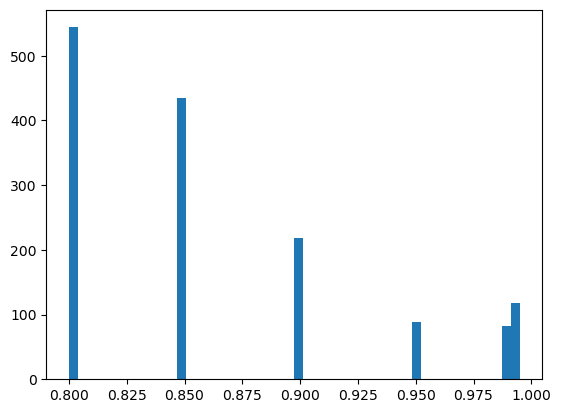

In [12]:
plt.hist(df_detections_neg["A_from_implant"], bins=50)

In [13]:
#let's calculate efficiency at this step
df_implants_neg_big = df_implants_neg[df_implants_neg["A_from_implant"]<.9]

In [14]:
df_implants_pos_big = df_implants_pos[df_implants_pos["A_from_implant"]>1.1]

In [15]:
print(len(df_implants_pos_big), len(df_implants_neg_big))

1309 1218


In [16]:
df_detections_pos_big = df_detections_pos[df_detections_pos["A_from_implant"]>1.1]
df_detections_neg_big = df_detections_neg[df_detections_neg["A_from_implant"]<.9]

In [17]:
print(len(df_detections_pos_big), len(df_detections_neg_big))

1394 978


In [18]:
print("efficiency before doing postprocessing cuts:")
print(len(df_detections_pos_big)/len(df_implants_pos_big), len(df_detections_neg_big)/len(df_implants_neg_big))

efficiency before doing postprocessing cuts:
1.0649350649350648 0.8029556650246306


In [ ]:
#this is after dropping duplicates but we may not have dropped
#the best duplicate in the pair so let's go back and not do that

In [96]:
# #i will combine them NO I CANT CAUSE THE IMAGES ARE SEPARATE
# df_detections_big = pd.concat(
#             [df_detections_pos_big, df_detections_neg_big], ignore_index=True
#                     )
# df_implants_big = pd.concat(
#             [df_implants_pos_big, df_implants_neg_big], ignore_index=True
#                     )

In [19]:
#pos
df_nocr_pos = df_detections_pos_big[df_detections_pos_big["type"] != "cr"]
df_reduced_edges_pos= rff.reduce_edges(df_nocr_pos, 15)
df_reduced_edges_size4_pos = rff.reduce_size(df_reduced_edges_pos, 4)

Number of transient candidates reduced from 1393 to 1390.
Number of transient candidates reduced from 1390 to 1377.


In [ ]:
df_second = rff.reduce_max_3(df_reduced_edges_size4

In [ ]:
norm = (file1_array-np.min(file1_array))/(np.max(file1_array)-np.min(file1_array))

In [26]:
count=0
for filename in np.unique(df_reduced_edges_size4_pos["filename"]):
    df_for_file = df_reduced_edges_size4_pos[df_reduced_edges_size4_pos["filename"]==filename]
    # print(df_for_file)
    fname = filename+"_1_implanted.npy"
    fpath = "/lustre/lrspec/ZTF_data/training_aug24/full_image_implantations/fullrange/images/"
    path = fpath+fname
    # hdul=fits.open(path)
    # image = hdul[1].data
    image = np.load(path)
    #now have to scale it up...
    # plt.imshow(image)
    background = rff.get_image_background(image)
#         #subtracting background
    imagenobackground = image - np.full(np.shape(image),background)
    reduced_df = rff.reduce_max_3(df_for_file, imagenobackground)
    if count==0:
        reduced_df2 = reduced_df
        count=1
    else:
        reduced_df2 = pd.concat(
            [reduced_df2, reduced_df], ignore_index=True
                    )
df_reducemax_pos = reduced_df2

In [27]:
df_reducemax_pos

,Unnamed: 0,filename,detection_size,type,row_from_nn,col_from_nn,row_from_implant,col_from_implant,A_from_implant,sig_from_implant
0,288,ztf_20220820237546_000798_zr_c01_x_0003.,196,pos,2575.357143,143.117347,151.0,2588.0,8.0,5.0
1,290,ztf_20220820237546_000798_zr_c01_x_0003.,161,pos,1561.732919,1031.652174,1045.0,1573.0,2.0,6.0
2,291,ztf_20220820237546_000798_zr_c01_x_0003.,130,pos,946.723077,1872.200000,1880.0,959.0,4.0,4.0
3,292,ztf_20220820237546_000798_zr_c01_x_0003.,270,pos,857.666667,2954.600000,2962.0,872.0,6.0,8.0
4,178,ztf_20220820237546_000798_zr_c02_x_0000.,91,pos,1685.593407,361.934066,371.0,1696.0,4.0,3.0
...,...,...,...,...,...,...,...,...,...,...
885,938,ztf_20221020138241_000686_zi_c08_x_0014.,267,pos,2486.520599,1051.393258,1062.0,2500.0,8.0,9.0
886,939,ztf_20221020138241_000686_zi_c08_x_0014.,68,pos,2025.705882,1935.411765,1946.0,2036.0,3.0,4.0
887,940,ztf_20221020138241_000686_zi_c08_x_0014.,171,pos,1771.192982,2975.520468,2985.0,1784.0,8.0,9.0
888,941,ztf_20221020138241_000686_zi_c08_x_0014.,242,pos,1570.483471,2377.041322,2388.0,1584.0,6.0,9.0


In [29]:
df_reduced_edges_size4_pos

,Unnamed: 0,filename,detection_size,type,row_from_nn,col_from_nn,row_from_implant,col_from_implant,A_from_implant,sig_from_implant
0,0,ztf_20220820237546_000798_zr_c14_x_0004.,436,both,1148.768349,418.321101,429.0,1157.0,10.0,6.0
1,1,ztf_20220820237546_000798_zr_c14_x_0004.,49,pos,2469.489796,1962.428571,1972.0,2480.0,1.3,4.0
2,2,ztf_20220820237546_000798_zr_c14_x_0004.,106,pos,2093.462264,2060.264151,2070.0,2104.0,1.5,5.0
3,3,ztf_20220820237546_000798_zr_c14_x_0004.,46,pos,1921.500000,366.456522,376.0,1933.0,1.3,5.0
4,4,ztf_20220820237546_000798_zr_c14_x_0004.,55,pos,1752.927273,343.436364,353.0,1763.0,2.0,3.0
...,...,...,...,...,...,...,...,...,...,...
1417,1417,ztf_20221020138241_000686_zi_c06_x_0009.,76,pos,2379.657895,1297.000000,1306.0,2393.0,1.5,8.0
1418,1418,ztf_20221020138241_000686_zi_c06_x_0009.,126,pos,1115.468254,1761.730159,1771.0,1126.0,3.0,4.0
1419,1419,ztf_20221020138241_000686_zi_c06_x_0009.,82,pos,917.890244,1739.707317,1749.0,928.0,2.0,3.0
1420,1420,ztf_20221020138241_000686_zi_c06_x_0009.,75,pos,494.226667,1033.960000,1044.0,505.0,1.3,4.0


In [ ]:
#now let's figure out the rest of the pipeline
'''

    df_second = get_second_df_for_lc(lc_filename, tolerance=10)
    for i, row2 in df_second.iterrows():
        # print(i)
        row_num = (int(row2['row_from_nn'])+10)
        if i==df_second.index[0]:
            plt.axvline(x=row_num,c='lightsteelblue', label = "eliminated: sobel ratio < 5 (cosmic ray)")
        else:
            plt.axvline(x=row_num,c='lightsteelblue')  
    df_third = get_third_df_for_lc(lc_filename, tolerance=10)
    for i, row in df_third.iterrows():
    # print(i)
        row_num = (int(row['row_from_nn'])+10)
        if i==df_third.index[0]:
            plt.axvline(x=row_num,c='pink', label = "eliminated: local snr<1")
        else:
            plt.axvline(x=row_num,c='pink')
        if np.abs(row['snr_center'])>25:
            plt.axvline(x=row_num,c='orange', label = "eliminated: moving object (snr>25)")
            
    #i definitely did not include anything with SNR>25 at this point but i dont think i saved that
    #the only other strict cut was local snr>1
    #if i add the simultaneity criterion then i suppose i should put that here as well
    
    df_last = get_last_df_for_lc(lc_filename)
    '''

In [37]:
def add_snr(df, half_aperture, tracking, fpath, extension):
    """
    returns the dataframe with a new column of stdv ratios
    see get_sobel_ratio(stamp) and get_stdv_ratio
    """
    ratios_center = np.zeros(len(df))
    ratios_max = np.zeros(len(df))
    ratios_min = np.zeros(len(df))
    for i, index in enumerate(df.index):
        # print(index)
        tot, maxcols = get_tot_npy(df, index, extension, half_aperture, tracking, fpath)
        stdv = rff.get_stdvs(tot, do_all=False, df=df, index=index)
        avg = np.average(tot)
        row = int(df.loc[index]["row_from_nn"]) + 10
        max_val = np.max(tot[row - 10 : row + 10])
        min_val = np.min(tot[row - 10 : row + 10])
        signal_center = tot[row] - avg
        signal_max = max_val - avg
        signal_min = min_val - avg
        ratios_center[i] = signal_center / stdv
        ratios_max[i] = signal_max / stdv
        ratios_min[i] = signal_min / stdv
    df["snr_center"] = ratios_center
    df["snr_max"] = ratios_max
    df["snr_min"] = ratios_min
    return df




def get_tot_npy(
    df,
    index, extension,
    half_aperture=2,
    tracking=True,
    fpath="/lustre/lrspec/ZTF_data/science_extractions/to_extract/1020_minus_extras/",
):
    """
    returns tot, maxcols: an array that is the flux of the star streak
    given an aperture that is halfaperture*2+1
    and if tracking=true, tracks when the streak posittion fluctuates
    oif tracking==false, goes based on average center of streak
    note: uses loc instead of iloc
    """
    wideval = half_aperture
    wid = 10
    fname = df.loc[index]["filename"] + extension
    row = (
        int(df.loc[index]["row_from_nn"]) + 10
    )  # we add 10 here bc that's the cnn offset of returned values
    col = int(df.loc[index]["col_from_nn"]) + 10
    quad = int(df.loc[index]["quadrant"])
    column = int(col)

    path = fpath + fname
    # print(path)
    file1_array = np.load(path)
    # norm = (file1_array-np.min(file1_array))/(np.max(file1_array)-np.min(file1_array)) #norm
    image = file1_array

    background = rff.get_image_background(image)

    imagenobackground = image - np.full(np.shape(image), background)

    if tracking == False:
        zeropoint = col - 7
        averages = np.average(
            imagenobackground[row - 10 : row + 10, zeropoint : zeropoint + 14], axis=0
        )
        maxind = np.argmax(averages)
        tot2 = np.zeros(imagenobackground.shape[0])
        for r in range(
            0, imagenobackground.shape[0]
        ):  # this should be each row, probably
            maxcol = zeropoint + maxind
            combined = imagenobackground[r, maxcol]
            for i in range(1, half_aperture + 1):
                combined += imagenobackground[r, maxcol - i]
                combined += imagenobackground[r, maxcol + i]
            tot2[r] = combined
        return tot2, np.full(len(tot2), maxcol)

    # so we need to track the whole streak
    # for each row, need to choose a column index
    tot = np.zeros(imagenobackground.shape[0])
    maxcols = np.zeros(imagenobackground.shape[0])
    zeropoint = col - 10
    for r in range(0, imagenobackground.shape[0]):  # this should be each row, probably
        maxcol = np.argmax(imagenobackground[r, zeropoint : zeropoint + 20]) + zeropoint
        maxcols[r] = maxcol
        combined = imagenobackground[r, maxcol]
        for i in range(1, half_aperture + 1):
            combined += imagenobackground[r, maxcol - i]
            combined += imagenobackground[r, maxcol + i]
        # combined = imagenobackground[r, maxcol-2] + imagenobackground[r, maxcol-1] + imagenobackground[r, maxcol] + imagenobackground[r, maxcol+1] + imagenobackground[r, maxcol+2]
        # print(combined)
        tot[r] = combined

    return tot, maxcols


def get_sobel_ratio(stamp):
    """
    input: stamp: 2d brightnesses array with candidate transient
    larger = less likely to be a cosmic ray
    returns sobel_ratio = np.max(Lx)/np.max(Ly) where x is columns axis and y is rows axis
    """
    
    Lx = sobel(stamp, axis=1)  # column axis
    Ly = sobel(stamp, axis=0)  # rows axis
    sobel_ratio = np.max(Lx) / np.max(Ly)  # we want this to be as large as possible
    return sobel_ratio


def get_stamp_from_df(index, fpath, df, extension, norm, quad=None):
    """
    returns a 20x20 numpy array of brightnesses centered around the detection
    located at index of dataframe df
    note that the filepath to the science images is hardcoded currently
    norm=True has the image normalized (not the stamp, the entire image)
    norm=False has it in terms of counts
    """
    fname = df.loc[index]["filename"] + extension
    row = int(df.loc[index]["row_from_nn"]) + 10
    col = int(df.loc[index]["col_from_nn"]) + 10
    if quad==None:
        quad = int(df.loc[index]["quadrant"])
    # if direcname == "0820":
    # fpath = (
    #     "/lustre/lrspec/ZTF_data/science_extractions/to_extract/"
    #     + direcname
    #     + "_minus_extras/"
    # )
    # else:
    # fpath = "/lustre/lrspec/ZTF_data/science_extractions/to_extract/"+direcname+"/"
    path = fpath + fname
    # hdul = fits.open(path)
    file1_array = np.load(path)
    if norm:
        normalized = (file1_array - np.min(file1_array)) / (
            np.max(file1_array) - np.min(file1_array)
        )  # norm
        stamp = normalized[row - 10 : row + 10, col - 10 : col + 10]
        # plt.imshow(stamp)
        # plt.colorbar()
        return stamp
        background = rff.get_image_background(normalized)
    stamp = file1_array[row - 10 : row + 10, col - 10 : col + 10]
    # plt.imshow(stamp)
    # plt.colorbar()
    background = rff.get_image_background(file1_array)
    plt.imshow(stamp)
    return stamp, background


def add_sobel_ratio(fpath, df, extension):
    """
    returns the dataframe with a new column of sobel ratios
    see get_sobel_ratio(stamp)
    """
    sobels = []
    for index in df.index:
        stamp, bg = get_stamp_from_df(index, fpath, df, extension, norm=False)
        sobelr = get_sobel_ratio(stamp)
        sobels.append(sobelr)
    df["sobel_ratio"] = sobels
    return df

In [30]:
df_detections_pos = df_reduced_edges_size4_pos

In [31]:
df_detections_pos["quadrant"] = np.full(len(df_detections_pos), 1)

/tmp/ipykernel_9481/2856257859.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_detections_pos["quadrant"] = np.full(len(df_detections_pos), 1)


In [32]:
fpath = "/lustre/lrspec/ZTF_data/training_aug24/full_image_implantations/fullrange/images/"

/tmp/ipykernel_9481/569356546.py:166: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["sobel_ratio"] = sobels


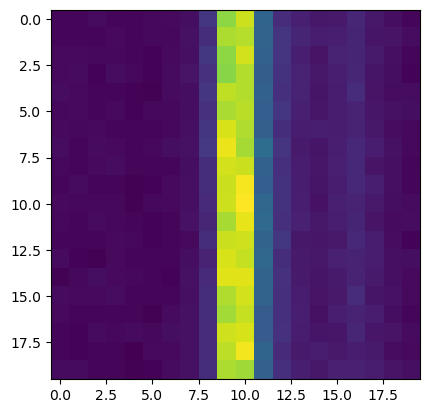

In [38]:
df_sobel_pos = add_sobel_ratio(fpath, df_detections_pos, extension="_1_implanted.npy")

In [44]:
np.sum(df_sobel_pos["sobel_ratio"]<5)

13

In [40]:
df_snr_pos = df_sobel_pos[df_sobel_pos["sobel_ratio"]>5]

In [41]:
df_snr_pos = add_snr(df_snr_pos, half_aperture=2, tracking=True, fpath=fpath, extension="_1_implanted.npy")

/tmp/ipykernel_9481/569356546.py:23: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["snr_center"] = ratios_center
/tmp/ipykernel_9481/569356546.py:24: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["snr_max"] = ratios_max
/tmp/ipykernel_9481/569356546.py:25: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexi

In [45]:
df_snr_pos

,Unnamed: 0,filename,detection_size,type,row_from_nn,col_from_nn,row_from_implant,col_from_implant,A_from_implant,sig_from_implant,quadrant,sobel_ratio,snr_center,snr_max,snr_min
0,0,ztf_20220820237546_000798_zr_c14_x_0004.,436,both,1148.768349,418.321101,429.0,1157.0,10.0,6.0,1,17.687725,-0.686704,1.094321,-2.406206
1,1,ztf_20220820237546_000798_zr_c14_x_0004.,49,pos,2469.489796,1962.428571,1972.0,2480.0,1.3,4.0,1,14.185999,2.664492,2.664492,-1.239475
2,2,ztf_20220820237546_000798_zr_c14_x_0004.,106,pos,2093.462264,2060.264151,2070.0,2104.0,1.5,5.0,1,22.496025,-0.088135,0.219191,-0.522768
3,3,ztf_20220820237546_000798_zr_c14_x_0004.,46,pos,1921.500000,366.456522,376.0,1933.0,1.3,5.0,1,20.006292,-0.224876,2.250085,-0.752826
4,4,ztf_20220820237546_000798_zr_c14_x_0004.,55,pos,1752.927273,343.436364,353.0,1763.0,2.0,3.0,1,11.722691,-1.140486,1.358961,-1.858089
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1417,1417,ztf_20221020138241_000686_zi_c06_x_0009.,76,pos,2379.657895,1297.000000,1306.0,2393.0,1.5,8.0,1,30.737625,0.745175,1.275340,-2.146864
1418,1418,ztf_20221020138241_000686_zi_c06_x_0009.,126,pos,1115.468254,1761.730159,1771.0,1126.0,3.0,4.0,1,24.196653,-1.822216,0.949394,-1.822216
1419,1419,ztf_20221020138241_000686_zi_c06_x_0009.,82,pos,917.890244,1739.707317,1749.0,928.0,2.0,3.0,1,17.215626,-0.570323,2.482265,-2.691228
1420,1420,ztf_20221020138241_000686_zi_c06_x_0009.,75,pos,494.226667,1033.960000,1044.0,505.0,1.3,4.0,1,21.157385,0.783683,2.253322,-1.320444


In [46]:
np.sum(np.abs(df_snr_pos["snr_center"])>25)

0

(array([303., 446., 444., 245., 141.,  85.,  73.,  24.,  20.,  13.,  19.,
         14.,  12.,  13.,  11.,  19.,   8.,  13.,  19.,   9.,  12.,  12.,
          6.,   4.,   5.,   2.,   7.,   6.,   6.,  11.,   7.,   5.,   5.,
          3.,   8.,   4.,   7.,   3.,   9.,   2.,   6.,   7.,   2.,   1.,
          7.,   1.,   1.,   2.,   2.,   2.,   4.,   1.,   3.,   0.,   2.,
          1.,   0.,   1.,   1.,   1.,   1.,   2.,   3.,   1.,   1.,   2.,
          2.,   0.,   0.,   0.,   1.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,   1.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   1.,   0.,
          2.]),
 array([ -5.7665494 ,  -0.69475073,   4.37704794,   9.44884661,
         14.52064528,  19.59244395,  24.66424262,  29.73604129,
         34.80783996,  39.87963863,  44.9514373 ,  50.02323597,
         55.09503464,  60.16683331,  65.23863198,  70.31043065,
         75.38222932,  80.45402799,  85.52582666,  90.59762533

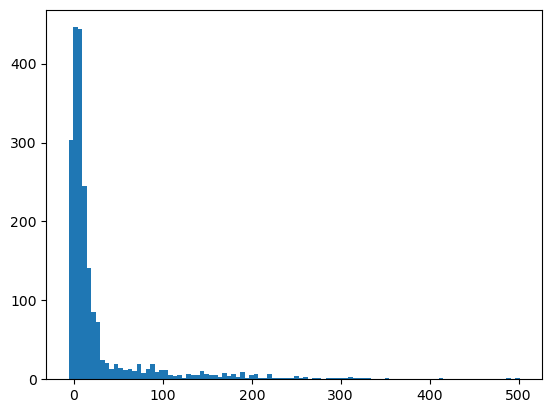

In [183]:
plt.hist(df_sobel_snr["snr_center"], bins=100)

In [47]:
df_snrcut_pos = df_snr_pos[np.abs(df_snr_pos["snr_center"])<25]

In [56]:
#local snr

def add_snr_integrated(df, extension, fpath, half_aperture=2, tracking=True, wid=10):
    """
    returns the dataframe with new columns for outputs of
    snr_local, snr_global, noise_local, noise_global, local_average_outside, height, FWHM 
    """
    column_names = ['snr_local', 'snr_global', 'noise_local', 'noise_global', 
                'local_average_outside', 'height', 'FWHM', 'signal_local']

    for col in column_names:
        df[col] = np.zeros(len(df))
    
    for index in df.index:
        # print(index)
        tot, maxcols = get_tot_npy(df, index, extension, half_aperture,  tracking, fpath)
        row = int(df.loc[index]["row_from_nn"]) + wid
        snr_local, snr_global, noise_local, noise_global, local_average_outside, height, FWHM, signal_local = rff.get_snr_integrated(tot, row)
        df.loc[index, column_names] = [snr_local, snr_global, noise_local, noise_global, local_average_outside, height, FWHM, signal_local]
    return df

In [57]:
df_snrall = add_snr_integrated(df_snrcut_pos, extension="_1_implanted.npy", fpath=fpath)

In [59]:
df_snrall_pos = df_snrall

In [1]:
#double streak

NameError: name 'fpath' is not defined

In [60]:
df_snrall_pos

,Unnamed: 0,filename,detection_size,type,row_from_nn,col_from_nn,row_from_implant,col_from_implant,A_from_implant,sig_from_implant,...,snr_max,snr_min,snr_local,snr_global,noise_local,noise_global,local_average_outside,height,FWHM,signal_local
0,0,ztf_20220820237546_000798_zr_c14_x_0004.,436,both,1148.768349,418.321101,429.0,1157.0,10.0,6.0,...,1.094321,-2.406206,0.141003,0.007484,33.583812,632.727277,1178.130959,75.647972,2.0,4.735424
1,1,ztf_20220820237546_000798_zr_c14_x_0004.,49,pos,2469.489796,1962.428571,1972.0,2480.0,1.3,4.0,...,2.664492,-1.239475,0.376764,0.089819,23.187314,97.264148,708.369398,61.892199,3.0,8.736149
2,2,ztf_20220820237546_000798_zr_c14_x_0004.,106,pos,2093.462264,2060.264151,2070.0,2104.0,1.5,5.0,...,0.219191,-0.522768,0.098536,0.216796,157.407446,71.543303,2106.278975,110.897017,5.0,15.510301
3,3,ztf_20220820237546_000798_zr_c14_x_0004.,46,pos,1921.500000,366.456522,376.0,1933.0,1.3,5.0,...,2.250085,-0.752826,0.567827,0.607795,22.817014,21.316595,634.969054,45.320497,7.0,12.956126
4,4,ztf_20220820237546_000798_zr_c14_x_0004.,55,pos,1752.927273,343.436364,353.0,1763.0,2.0,3.0,...,1.358961,-1.858089,0.464733,0.460789,14.102132,14.222841,390.801381,20.511394,4.0,6.553725
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1417,1417,ztf_20221020138241_000686_zi_c06_x_0009.,76,pos,2379.657895,1297.000000,1306.0,2393.0,1.5,8.0,...,1.275340,-2.146864,0.244805,0.231747,56.516540,59.700963,2212.189487,83.800259,5.0,13.835543
1418,1418,ztf_20221020138241_000686_zi_c06_x_0009.,126,pos,1115.468254,1761.730159,1771.0,1126.0,3.0,4.0,...,0.949394,-1.822216,0.304599,0.045034,49.469976,334.600501,1702.970122,70.396089,5.0,15.068515
1419,1419,ztf_20221020138241_000686_zi_c06_x_0009.,82,pos,917.890244,1739.707317,1749.0,928.0,2.0,3.0,...,2.482265,-2.691228,0.229316,0.071484,24.403988,78.286793,1145.883520,46.763819,2.0,5.596226
1420,1420,ztf_20221020138241_000686_zi_c06_x_0009.,75,pos,494.226667,1033.960000,1044.0,505.0,1.3,4.0,...,2.253322,-1.320444,0.261914,0.246523,55.889513,59.378835,2515.767659,110.259197,4.0,14.638254


In [62]:
from scipy.signal import find_peaks

In [68]:
def has_two_streaks(df, index, fpath, extension, prominence=15, return_properties=False):
    '''
    will return true if it has two streaks, otherwise false
    '''
    fname = df.loc[index]["filename"]+extension
    row = int(df.loc[index]["row_from_nn"])+10
    col = int(df.loc[index]["col_from_nn"])+10
    quad = int(df.loc[index]["quadrant"])
    # if direcname == "0820":
    # fpath = "/lustre/lrspec/ZTF_data/science_extractions/to_extract/"+direcname+"_minus_extras/"
    # else:
        # fpath = "/lustre/lrspec/ZTF_data/science_extractions/to_extract/"+direcname+"/"
    path = fpath+fname
    # print(path)
    # hdul = fits.open(path)
    # file1_array = hdul[quad].data
    file1_array = np.load(path)

    averages = np.average(file1_array[row-15:row+15, col-15:col+15], axis=0)
    plt.plot(averages)
    peaks, properties = find_peaks(averages, prominence=prominence)
    # print(peaks)
    # print(properties['prominences'])
    if len(peaks)>1:
        if return_properties==True:
            return True, properties
        return True #, properties
    else:
        return False

    


In [70]:
def add_twostreaks(df, extension, fpath, name="has_two_streaks",prominence=20):
    two_streaks = []
    for index in df.index:
        value = has_two_streaks(df, index, fpath, extension, prominence=prominence)
        two_streaks.append(value)
    df[name] = two_streaks
    return df

In [78]:
fpath

'/lustre/lrspec/ZTF_data/training_aug24/full_image_implantations/fullrange/images/'

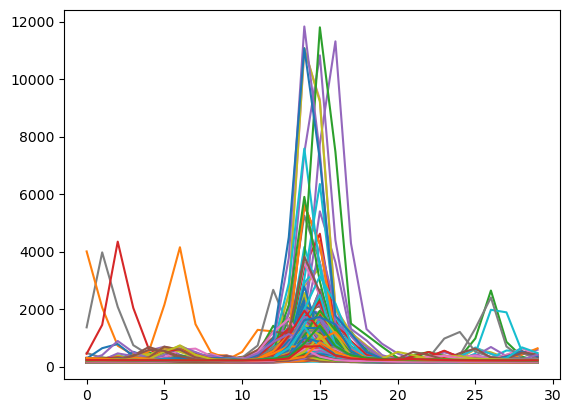

In [74]:
df_wstreaks_pos = add_twostreaks(df_snrall_pos, extension="_1_implanted.npy", fpath=fpath, name="has_two_streaks",prominence=20)

In [79]:
df_nodoubles_pos = df_wstreaks_pos[df_wstreaks_pos["has_two_streaks"]==False]

In [ ]:
#todo at end:
#check duplicates
#see how many there are that were mischaracterized as pos/neg

In [87]:
df_nodoubles_pos.duplicated(["filename", "row_from_implant", "col_from_implant"])

1       False
3       False
4       False
6       False
9       False
        ...  
1415    False
1417    False
1418     True
1419    False
1420    False
Length: 827, dtype: bool

In [92]:
np.sum(df_detections_neg["type"]=='pos')

752

In [95]:
len(df_detections_neg_big)

978

In [93]:
np.sum(df_detections_neg.duplicated(["filename", "row_from_implant", "col_from_implant"]))

1086

In [265]:

# Step 1: Set the folder path where your DataFrames are stored
folder_path = (
    "/lustre/lrspec/ZTF_data/training_aug24/full_image_implantations/predsarrays"
)
path_to_save = "/lustre/lrspec/ZTF_data/training_aug24/full_image_implantations/"

# Step 2: List all the files in the folder
files = [
    f for f in os.listdir(folder_path) if f.endswith("npy1alllist")
]  # Adjust this to your file format

# Step 3: Read all DataFrames and add the filename as a new column
df_implants = pd.DataFrame([])
counter = 0

for f in files:
    df = pd.read_csv(os.path.join(folder_path, f))
    filename_start = df["filename"][1]
    infopath = (
        path_to_save
        + "info/"
        + str(filename_start)
        + "_"
        + str(1)
        + "_implanted_info.npy"
    )
    infos = np.load(infopath)
    # print(info)
    if counter == 0:
         df_implants["filename"] = np.full(len(infos),filename_start)

         df_implants["row_from_implant"] = infos[:,0]
         df_implants["col_from_implant"] = infos[:,1]
         df_implants["A_from_implant"] = infos[:,2]
         df_implants["sig_from_implant"] = infos[:,3]
         counter = 1
    else:
         print("adding")
         df_implants2 = pd.DataFrame([])

         df_implants2["filename"] = np.full(len(infos),filename_start)

         df_implants2["row_from_implant"] = infos[:,0]
         df_implants2["col_from_implant"] = infos[:,1]
         df_implants2["A_from_implant"] = infos[:,2]
         df_implants2["sig_from_implant"] = infos[:,3]

         df_implants = pd.concat(
            [df_implants2, df_implants], ignore_index=True
                    )
df_implants_pos = df_implants

adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding
adding

In [267]:
len(df_implants_pos)

1797

In [271]:
len(df_implants_pos_big)

1472

In [270]:
df_implants_pos_big = df_implants_pos[df_implants_pos["A_from_implant"]>=1.1]


In [272]:
df_implants_pos_big.to_csv(
    "/lustre/lrspec/ZTF_data/training_aug24/full_image_implantations/fullrange/df_implants_pos_big"
)

In [99]:
df_reducemax_pos

,Unnamed: 0,filename,detection_size,type,row_from_nn,col_from_nn,row_from_implant,col_from_implant,A_from_implant,sig_from_implant
0,288,ztf_20220820237546_000798_zr_c01_x_0003.,196,pos,2575.357143,143.117347,151.0,2588.0,8.0,5.0
1,290,ztf_20220820237546_000798_zr_c01_x_0003.,161,pos,1561.732919,1031.652174,1045.0,1573.0,2.0,6.0
2,291,ztf_20220820237546_000798_zr_c01_x_0003.,130,pos,946.723077,1872.200000,1880.0,959.0,4.0,4.0
3,292,ztf_20220820237546_000798_zr_c01_x_0003.,270,pos,857.666667,2954.600000,2962.0,872.0,6.0,8.0
4,178,ztf_20220820237546_000798_zr_c02_x_0000.,91,pos,1685.593407,361.934066,371.0,1696.0,4.0,3.0
...,...,...,...,...,...,...,...,...,...,...
885,938,ztf_20221020138241_000686_zi_c08_x_0014.,267,pos,2486.520599,1051.393258,1062.0,2500.0,8.0,9.0
886,939,ztf_20221020138241_000686_zi_c08_x_0014.,68,pos,2025.705882,1935.411765,1946.0,2036.0,3.0,4.0
887,940,ztf_20221020138241_000686_zi_c08_x_0014.,171,pos,1771.192982,2975.520468,2985.0,1784.0,8.0,9.0
888,941,ztf_20221020138241_000686_zi_c08_x_0014.,242,pos,1570.483471,2377.041322,2388.0,1584.0,6.0,9.0


In [100]:
df_reduced_edges_size4_pos

,Unnamed: 0,filename,detection_size,type,row_from_nn,col_from_nn,row_from_implant,col_from_implant,A_from_implant,sig_from_implant,quadrant,sobel_ratio
0,0,ztf_20220820237546_000798_zr_c14_x_0004.,436,both,1148.768349,418.321101,429.0,1157.0,10.0,6.0,1,17.687725
1,1,ztf_20220820237546_000798_zr_c14_x_0004.,49,pos,2469.489796,1962.428571,1972.0,2480.0,1.3,4.0,1,14.185999
2,2,ztf_20220820237546_000798_zr_c14_x_0004.,106,pos,2093.462264,2060.264151,2070.0,2104.0,1.5,5.0,1,22.496025
3,3,ztf_20220820237546_000798_zr_c14_x_0004.,46,pos,1921.500000,366.456522,376.0,1933.0,1.3,5.0,1,20.006292
4,4,ztf_20220820237546_000798_zr_c14_x_0004.,55,pos,1752.927273,343.436364,353.0,1763.0,2.0,3.0,1,11.722691
...,...,...,...,...,...,...,...,...,...,...,...,...
1417,1417,ztf_20221020138241_000686_zi_c06_x_0009.,76,pos,2379.657895,1297.000000,1306.0,2393.0,1.5,8.0,1,30.737625
1418,1418,ztf_20221020138241_000686_zi_c06_x_0009.,126,pos,1115.468254,1761.730159,1771.0,1126.0,3.0,4.0,1,24.196653
1419,1419,ztf_20221020138241_000686_zi_c06_x_0009.,82,pos,917.890244,1739.707317,1749.0,928.0,2.0,3.0,1,17.215626
1420,1420,ztf_20221020138241_000686_zi_c06_x_0009.,75,pos,494.226667,1033.960000,1044.0,505.0,1.3,4.0,1,21.157385


In [133]:
#let's check out what we got

df_onestreak_neg = pd.read_csv("/lustre/lrspec/ZTF_data/training_aug24/full_image_implantations/fullrange/df_onestreak_neg")

In [134]:
justneg = df_onestreak_neg[df_onestreak_neg['type']=='neg']

In [135]:
len(justneg), np.sum(justneg["snr_local"]>1)

(208, 58)

In [183]:
df_detections_neg_big=pd.read_csv(
    "/lustre/lrspec/ZTF_data/training_aug24/full_image_implantations/fullrange/df_detections_neg_big"
)

In [154]:
df_reduced_edges_size4_pos = pd.read_csv(
    "/lustre/lrspec/ZTF_data/training_aug24/full_image_implantations/fullrange/df_reduced_edges_size4_pos"
)

In [182]:
df_detections_neg_big.to_csv(
    "/lustre/lrspec/ZTF_data/training_aug24/full_image_implantations/fullrange/df_detections_neg_big"
)

In [181]:
df_detections_neg_big = df_detections_neg[df_detections_neg["A_from_implant"]<=.9]

In [184]:
len(df_detections_neg), len(df_detections_neg_big), len(df_detections_neg[df_detections_neg["A_from_implant"]<=.9])

(1484, 1196, 1196)

In [173]:
df_implants_pos_bi = pd.read_csv(
    "/lustre/lrspec/ZTF_data/training_aug24/full_image_implantations/fullrange/df_implants_pos_big"
)

In [174]:
len(df_implants_pos_bi)

1472

In [167]:
df_detections_pos_big = df_detections_pos[df_detections_pos["A_from_implant"]>=1.1]

In [170]:
df_detections_pos_big.to_csv(
    "/lustre/lrspec/ZTF_data/training_aug24/full_image_implantations/fullrange/df_detections_pos_big")

In [185]:
df_onestreak_pos=pd.read_csv(
    "/lustre/lrspec/ZTF_data/training_aug24/full_image_implantations/fullrange/df_onestreak_pos")

In [188]:
justpos = df_onestreak_pos[df_onestreak_pos['type']=='pos']

In [186]:
df_onestreak_pos

,Unnamed: 0.2,Unnamed: 0.1,Unnamed: 0,filename,detection_size,type,row_from_nn,col_from_nn,row_from_implant,col_from_implant,...,snr_min,snr_local,snr_global,noise_local,noise_global,local_average_outside,height,FWHM,signal_local,has_two_streaks
0,3,292,292,ztf_20220820237546_000798_zr_c01_x_0003.,270,pos,857.666667,2954.600000,2962.0,872.0,...,-2.368055,0.509111,0.067366,25.512435,192.806190,1019.834891,42.984366,6.0,12.988659,False
1,14,30,30,ztf_20220820237546_000798_zr_c03_x_0000.,294,both,798.965986,2500.608844,2510.0,808.0,...,-0.584789,0.245480,0.209557,25.707024,30.113833,893.848600,50.212436,2.0,6.310571,False
2,15,32,32,ztf_20220820237546_000798_zr_c03_x_0000.,117,pos,795.897436,2501.213675,2510.0,808.0,...,-0.600836,0.458559,0.384973,25.277650,30.109362,893.166892,59.962258,4.0,11.591285,False
3,16,34,34,ztf_20220820237546_000798_zr_c03_x_0000.,198,pos,348.222222,494.303030,506.0,360.0,...,-2.305703,0.105783,0.056570,107.626075,201.255106,5641.689236,121.946018,3.0,11.385028,False
4,18,317,317,ztf_20220820237546_000798_zr_c03_x_0004.,190,pos,2773.768421,2500.126316,2510.0,2786.0,...,-3.342597,0.551309,0.042500,21.272862,275.952194,896.299870,54.391301,4.0,11.727924,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
466,876,164,164,ztf_20221020138241_000686_zi_c07_x_0013.,184,both,2799.777174,1787.831522,1800.0,2806.0,...,-1.446594,0.162626,0.160002,266.730944,271.105773,11122.680571,308.347563,10.0,43.377477,False
467,878,166,166,ztf_20221020138241_000686_zi_c07_x_0013.,185,pos,2898.481081,1663.243243,1671.0,2912.0,...,-1.797980,0.286508,0.091180,27.895921,87.655353,1128.349330,52.180944,3.0,7.992392,False
468,879,167,167,ztf_20221020138241_000686_zi_c07_x_0013.,107,pos,2795.149533,1788.383178,1800.0,2806.0,...,-1.387926,0.092549,0.093977,275.738718,271.548761,11127.487700,313.154692,4.0,25.519336,False
469,893,229,229,ztf_20221020138241_000686_zi_c07_x_0025.,8,pos,2008.500000,1786.000000,1800.0,2019.0,...,-0.760578,0.116691,0.105022,222.504928,247.227641,11195.702480,415.872715,4.0,25.964356,False


In [190]:
justpos_snrcut = justpos[justpos["snr_local"]>1]

In [191]:
justpos_snrcut.drop_duplicates(subset=["filename", "row_from_nn", "col_from_nn"])

,Unnamed: 0.2,Unnamed: 0.1,Unnamed: 0,filename,detection_size,type,row_from_nn,col_from_nn,row_from_implant,col_from_implant,...,snr_min,snr_local,snr_global,noise_local,noise_global,local_average_outside,height,FWHM,signal_local,has_two_streaks
90,141,312,312,ztf_20221014162894_000802_zg_c01_x_0009.,241,pos,1823.174274,1321.759336,1332.0,1837.0,...,3.748687,1.664837,3.802571,63.46187,27.784798,696.604016,684.189685,21.0,105.653672,False


In [2]:
df_names_neg = ["df_detections_neg_big", 
            "df_implants_neg_big",
           "df_nocr_neg",
           "df_reduced_edges_neg",
           "df_reduced_edges_size4_neg",
            "df_reducemax_neg",
            "df_sobel_neg", #not actually cut for sobel until next df
            "df_snr_neg", #not actually cut for snr until next df
            "df_snrall_neg",
            "df_wstreaks_neg",
            "df_onestreak_neg",
                # "df_snrcut_neg"
           ]

base_path = "/lustre/lrspec/ZTF_data/training_aug24/full_image_implantations/fullrange/"

dfs_neg = {
    name: pd.read_csv(f"{base_path}{name}")
    for name in df_names_neg
}

In [3]:
df_names_pos = ["df_detections_pos_big", 
            "df_implants_pos_big",
           "df_nocr_pos",
           "df_reduced_edges_pos",
           "df_reduced_edges_size4_pos",
            "df_reducemax_pos",
            "df_sobel_pos", #not actually cut for sobel until next df
            "df_snr_pos", #not actually cut for snr until next df
            "df_snrall_pos",
            "df_wstreaks_pos",
            "df_onestreak_pos",
                # "df_snrcut_pos"
           ]

base_path = "/lustre/lrspec/ZTF_data/training_aug24/full_image_implantations/fullrange/"

dfs_pos = {
    name: pd.read_csv(f"{base_path}{name}")
    for name in df_names_pos
}

In [292]:
for name, df in dfs_pos.items():
    print(name, df.shape)

df_detections_pos_big (1417, 11)
df_implants_pos_big (1472, 6)
df_nocr_pos (1416, 12)
df_reduced_edges_pos (1412, 12)
df_reduced_edges_size4_pos (1391, 12)
df_reducemax_pos (902, 13)
df_sobel_pos (902, 15)
df_snr_pos (899, 18)
df_snrall_pos (899, 26)
df_wstreaks_pos (899, 27)
df_onestreak_pos (471, 27)
df_snrcut_pos (1, 27)


In [293]:
for name, df in dfs_pos.items():
    if name!= "df_implants_pos_big":
        print(name, np.sum(df["type"]=="pos"))

df_detections_pos_big 1259
df_nocr_pos 1259
df_reduced_edges_pos 1255
df_reduced_edges_size4_pos 1234
df_reducemax_pos 786
df_sobel_pos 786
df_snr_pos 783
df_snrall_pos 783
df_wstreaks_pos 783
df_onestreak_pos 409
df_snrcut_pos 1


In [220]:
for name, df in dfs_pos.items():
    if name!= "df_implants_pos_big":
        print(name, np.sum(df.duplicated(subset=["filename", "row_from_nn", "col_from_nn"])))
        
        

df_detections_pos_big 0
df_nocr_pos 0
df_reduced_edges_pos 0
df_reduced_edges_size4_pos 0
df_reducemax_pos 0
df_sobel_pos 0
df_snr_pos 0
df_snrall_pos 0
df_wstreaks_pos 0
df_onestreak_pos 0


In [284]:
for name, df in dfs_neg.items():
    if name!= "df_implants_neg_big":
        print(name, len(df), np.sum(df["type"]=="neg"), np.sum(df.duplicated(subset=["filename", "row_from_nn", "col_from_nn"])))

df_detections_neg_big 1196 622 600
df_nocr_neg 1192 622 598
df_reduced_edges_neg 1188 622 596
df_reduced_edges_size4_neg 872 478 438
df_reducemax_neg 0 0 0
df_sobel_neg 0 0 0
df_snr_neg 0 0 0
df_snrall_neg 0 0 0
df_wstreaks_neg 0 0 0
df_onestreak_neg 0 0 0
df_snrcut_neg 0 0 0


In [222]:
len(df_implants_neg_big)

1218

In [295]:
for name, df in dfs_neg.items():
    if name!= "df_implants_neg_big":
        newdf = df[df["type"]=="neg"]
        print(name, len(newdf.drop_duplicates(subset=["filename", "row_from_nn", "col_from_nn"])))

df_detections_neg_big 309
df_nocr_neg 309
df_reduced_edges_neg 309
df_reduced_edges_size4_neg 237
df_reducemax_neg 183
df_sobel_neg 183
df_snr_neg 183
df_snrall_neg 183
df_wstreaks_neg 183
df_onestreak_neg 102
df_snrcut_neg 28


In [278]:
for name, df in dfs_pos.items():
    if name!= "df_implants_pos_big":
        newdf = df[df["type"]=="pos"]
        print(name, len(newdf.drop_duplicates(subset=["filename", "row_from_nn", "col_from_nn"])))

df_detections_pos_big 1259
df_nocr_pos 1259
df_reduced_edges_pos 1255
df_reduced_edges_size4_pos 1234
df_reducemax_pos 786
df_sobel_pos 786
df_snr_pos 783
df_snrall_pos 783
df_wstreaks_pos 783
df_onestreak_pos 409
df_snrcut_pos 1


In [240]:
df_snrcut_pos = df_onestreak_pos[df_onestreak_pos["snr_local"]>1]

In [241]:
df_snrcut_pos

,Unnamed: 0.2,Unnamed: 0.1,Unnamed: 0,filename,detection_size,type,row_from_nn,col_from_nn,row_from_implant,col_from_implant,...,snr_min,snr_local,snr_global,noise_local,noise_global,local_average_outside,height,FWHM,signal_local,has_two_streaks
90,141,312,312,ztf_20221014162894_000802_zg_c01_x_0009.,241,pos,1823.174274,1321.759336,1332.0,1837.0,...,3.748687,1.664837,3.802571,63.46187,27.784798,696.604016,684.189685,21.0,105.653672,False


In [243]:
df_snrcut_pos.to_csv(
    "/lustre/lrspec/ZTF_data/training_aug24/full_image_implantations/fullrange/df_snrcut_pos"
)

In [249]:
df.drop_duplicates?

ValueError: The truth value of a DataFrame is ambiguous. Use a.empty, a.bool(), a.item(), a.any() or a.all().

In [285]:
count=0
for filename in np.unique(df_reduced_edges_size4_pos["filename"]):
    
    df_for_file = df_reduced_edges_size4_pos[df_reduced_edges_size4_pos["filename"]==filename]
    # print(df_for_file)
    fname = filename+"_1_implanted.npy"
    fpath = "/lustre/lrspec/ZTF_data/training_aug24/full_image_implantations/fullrange/images/"
    path = fpath+fname
    # hdul=fits.open(path)
    # image = hdul[1].data
    image = np.load(path)
    #now have to scale it up...
    # plt.imshow(image)
    background = rff.get_image_background(image)
#         #subtracting background
    imagenobackground = image - np.full(np.shape(image),background)
    reduced_df = rff.reduce_max_3(df_for_file, imagenobackground)
    if count==0:
        reduced_df2 = reduced_df
        count=1
    else:
        reduced_df2 = pd.concat(
            [reduced_df2, reduced_df], ignore_index=True
                    )
    break


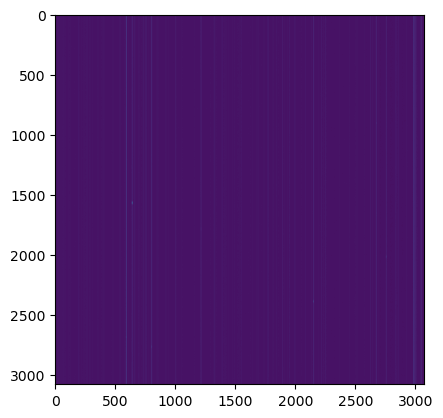

In [289]:
plt.imshow(np.sqrt(image))

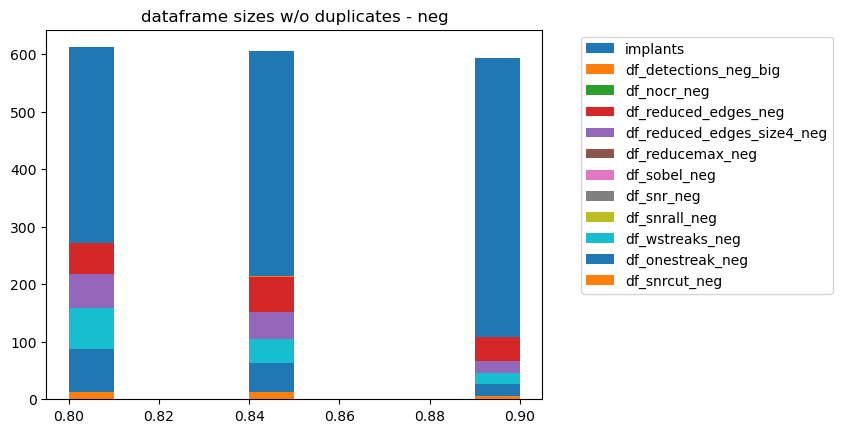

In [294]:
plt.hist(df_implants_neg_big["A_from_implant"],
         label="implants")
for name, df in dfs_neg.items():
    if name!= "df_implants_neg_big":
        plt.hist(df.drop_duplicates(subset=["filename", "row_from_nn", "col_from_nn"])["A_from_implant"],
                label=name)
plt.title("dataframe sizes w/o duplicates - neg")
plt.legend(bbox_to_anchor=(1.6, 1))

In [275]:
len(df_implants_pos_big), len(df_detections_pos_big.drop_duplicates(subset=["filename", "row_from_nn", "col_from_nn"]))

(1472, 1417)

In [309]:
np.unique(df_implants_pos_big["A_from_implant"])-.05

array([1.05, 1.25, 1.45, 1.95, 2.95, 3.95, 5.95, 7.95, 9.95])

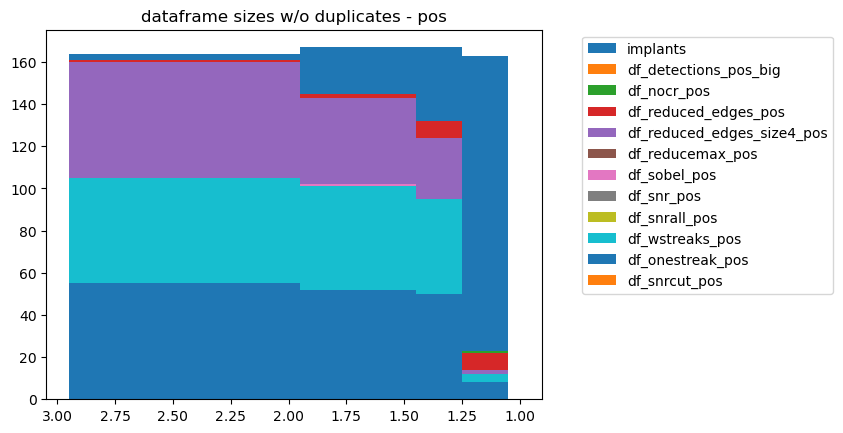

In [311]:
# binbounds = [1.0,1.1,1.2,1.3,1.4,1.5] #[2,3,4,5,7,9,10] #
binbounds = [1.0]+list(np.unique(df_implants_pos_big["A_from_implant"])-.05)[:5]
plt.hist(df_implants_pos_big["A_from_implant"],
         label="implants", bins=binbounds)
for name, df in dfs_pos.items():
    if name!= "df_implants_pos_big":
        plt.hist(df.drop_duplicates(subset=["filename", "row_from_nn", "col_from_nn"])["A_from_implant"],
                label=name, bins=binbounds)
plt.title("dataframe sizes w/o duplicates - pos")
plt.legend(bbox_to_anchor=(1.6, 1))
plt.gca().invert_xaxis()

(array([88.,  0.,  0.,  0., 63.,  0.,  0.,  0.,  0., 26.]),
 array([0.8 , 0.81, 0.82, 0.83, 0.84, 0.85, 0.86, 0.87, 0.88, 0.89, 0.9 ]),
 <BarContainer object of 10 artists>)

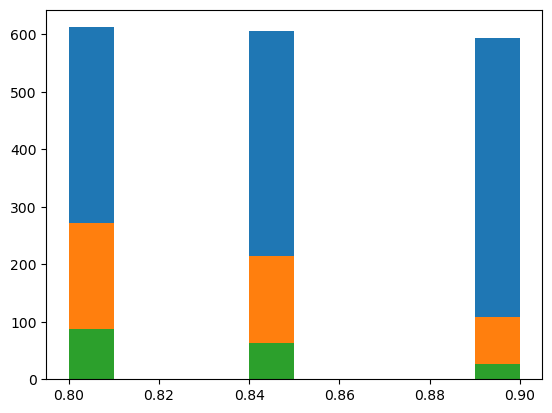

In [261]:
plt.hist(df_implants_neg_big["A_from_implant"])
plt.hist(df_detections_neg_big.drop_duplicates(subset=["filename", "row_from_nn", "col_from_nn"])["A_from_implant"])
plt.hist(df_onestreak_neg.drop_duplicates(subset=["filename", "row_from_nn", "col_from_nn"])["A_from_implant"])

In [20]:
importlib.reload(rff)

<module 'review_findings_functions' from '/home/3155/rwe/review_findings_functions.py'>

In [8]:
fpath = "/lustre/lrspec/ZTF_data/training_aug24/full_image_implantations/fullrange/images/"


In [213]:
dfs_neg['df_onestreak_neg'][:2]

,Unnamed: 0.3,Unnamed: 0.2,Unnamed: 0.1,Unnamed: 0,filename,detection_size,type,row_from_nn,col_from_nn,row_from_implant,...,snr_min,snr_local,snr_global,noise_local,noise_global,local_average_outside,height,FWHM,signal_local,has_two_streaks
0,2,469,587,587,ztf_20220820237546_000798_zr_c03_x_0000.,27,neg,1814.148148,491.888889,506.0,...,-1.714436,0.558774,0.460482,95.547602,115.942765,5679.445178,259.836292,15.0,53.389525,False
1,3,471,589,589,ztf_20220820237546_000798_zr_c03_x_0000.,35,neg,883.057143,2499.742857,2510.0,...,-3.474853,0.900174,0.856622,27.807476,29.221255,907.735548,108.724012,8.0,25.031580,False


In [229]:
dfs_neg['df_onestreak_neg'][dfs_neg['df_onestreak_neg']["Unnamed: 0"]==589].index[0]

1

In [399]:
def inspect_stamp_and_map(df, index, posneg, size=10, column=None):
    wid = 10
    if column!=None:
        index = df[df[column]==index].index[0]
    if posneg=="pos":
        extension = "_1_implanted.npy"
    elif posneg=="neg":
        extension = "_1_implanted_neg.npy"
    fig, ax = plt.subplots(1, 3, figsize=(7,5))
    fname = df.iloc[index]["filename"] + extension
    # print(df.iloc[index]["filename"])
    row = int(df.iloc[index]["row_from_nn"])
    col = int(df.iloc[index]["col_from_nn"])
    fpath = '/lustre/lrspec/ZTF_data/training_aug24/full_image_implantations/fullrange/images/'
    path = fpath + fname
    array = np.load(path)
    imj = ax[0].imshow(
                
                    array[
                        row - size + wid : row + size + wid,
                        col + wid - size : col + wid + size,
                    ]
                
                )
    nrow, ncol = array.shape
    ppath = "/lustre/lrspec/ZTF_data/training_aug24/full_image_implantations/predsarrays/"
#     if posneg =="pos":
#         pfile = df.iloc[index]["filename"]+"_extraction_predsarray_predsarray.npy"
#         predsarray = np.load(ppath+pfile)
#         pimg = predsarray[:, 1].reshape(ncol - 2 * wid, nrow - 2 * wid)
#     elif posneg=="neg":
#         pfile = df.iloc[index]["filename"]+"_extraction_predsarray_neg_predsarray.npy"
#         predsarray = np.load(ppath+pfile)
#         pimg = predsarray[:, 2].reshape(ncol - 2 * wid, nrow - 2 * wid)
#     ax[1].imshow(
        
#                     pimg[
#                         col - size : col + size,
#                         row  - size : row  + size,
#                     ].T>.9999
#                 )
    pfile_pos = df.iloc[index]["filename"]+"_extraction_predsarray_predsarray.npy"
    predsarray_pos = np.load(ppath+pfile_pos)
    pimg_pos = predsarray_pos[:, 1].reshape(ncol - 2 * wid, nrow - 2 * wid)
    pfile_neg = df.iloc[index]["filename"]+"_extraction_predsarray_neg_predsarray.npy"
    predsarray_neg = np.load(ppath+pfile_neg)
    pimg_neg = predsarray_neg[:, 2].reshape(ncol - 2 * wid, nrow - 2 * wid)
    ax[1].imshow(
        
                    pimg_neg[
                        col - size : col + size,
                        row  - size : row  + size,
                    ].T>.9999
                )
    ax[2].imshow(pimg_pos[
                        col - size : col + size,
                        row  - size : row  + size,
                    ].T>.9999
                )            
    ax[0].annotate(
    "Injection",
    xy=(  df["row_from_implant"].iloc[index]-col-wid+size,df["col_from_implant"].iloc[index]-row-wid+size),
    xytext=(size+3*size/4, size/2),  
    arrowprops=dict(
        facecolor="red",
        edgecolor="red",
        # shrink=1.0,
        # headlength=5,
        # headwidth=3,
    ),
    color="white",
    fontsize=10,
    ha="center",
    # va="top",
    rotation=0,
    zorder=10,
)
    ax[0].set_title("Injected image, Index "+str(index)+ ", A = "+str(df["A_from_implant"].iloc[index])+", sig = "+str(df["sig_from_implant"].iloc[index]))
    ax[1].set_title("CNN neg prediction")
    ax[2].set_title("CNN pos prediction")
    # print(df["row_from_implant"].iloc[index], col, df["col_from_implant"].iloc[index], row)
    fig.colorbar(imj, orientation='horizontal')
    plt.show()

In [166]:
dfs_neg['df_onestreak_neg'].iloc[0]

Unnamed: 0.3                                                    2
Unnamed: 0.2                                                  469
Unnamed: 0.1                                                  587
Unnamed: 0                                                    587
filename                 ztf_20220820237546_000798_zr_c03_x_0000.
detection_size                                                 27
type                                                          neg
row_from_nn                                           1814.148148
col_from_nn                                            491.888889
row_from_implant                                            506.0
col_from_implant                                           1825.0
A_from_implant                                                0.9
sig_from_implant                                              8.0
quadrant                                                        1
sobel_ratio                                             29.677061
snr_center

In [320]:
extension

NameError: name 'extension' is not defined

In [319]:
image = np.load(fpath+"ztf_20220820237546_000798_zr_c03_x_0000._

'/lustre/lrspec/ZTF_data/training_aug24/full_image_implantations/fullrange/images/'

In [318]:
dfs_neg['df_onestreak_neg'].iloc[0]

Unnamed: 0.3                                                    2
Unnamed: 0.2                                                  469
Unnamed: 0.1                                                  587
Unnamed: 0                                                    587
filename                 ztf_20220820237546_000798_zr_c03_x_0000.
detection_size                                                 27
type                                                          neg
row_from_nn                                           1814.148148
col_from_nn                                            491.888889
row_from_implant                                            506.0
col_from_implant                                           1825.0
A_from_implant                                                0.9
sig_from_implant                                              8.0
quadrant                                                        1
sobel_ratio                                             29.677061
snr_center

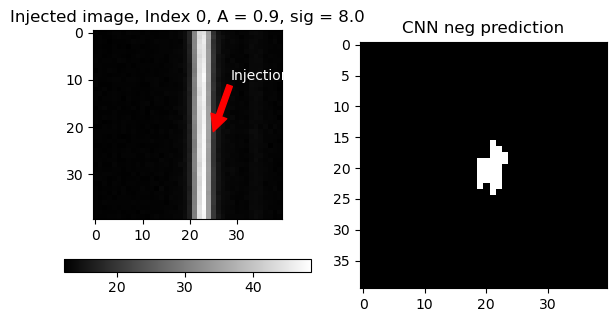

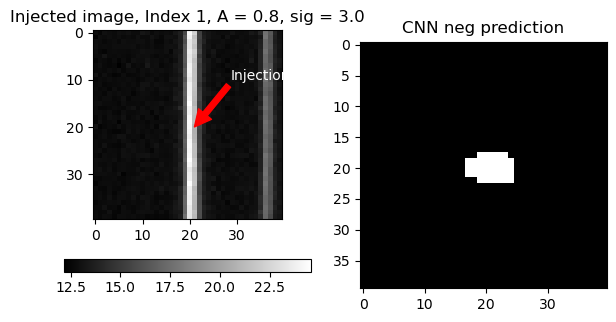

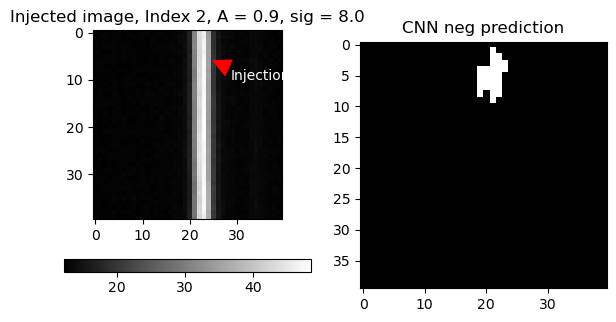

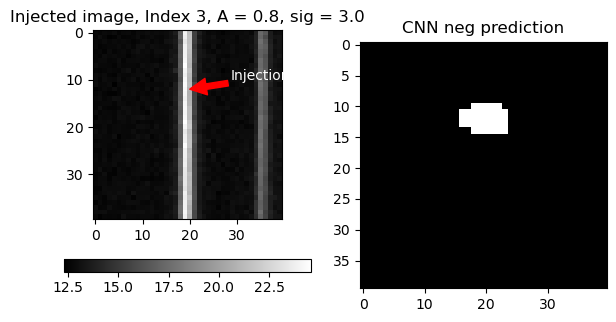

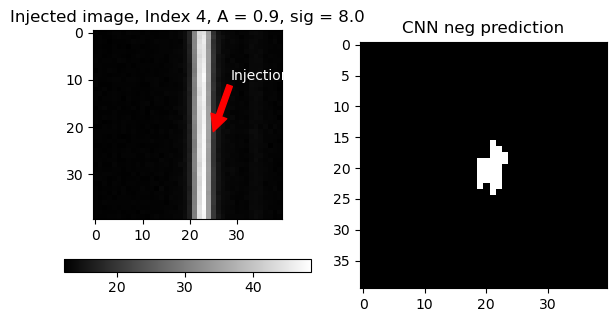

In [317]:
for index in dfs_neg['df_onestreak_neg'].index[:5]:
    inspect_stamp_and_map(dfs_neg['df_onestreak_neg'], index, "neg", size=20)

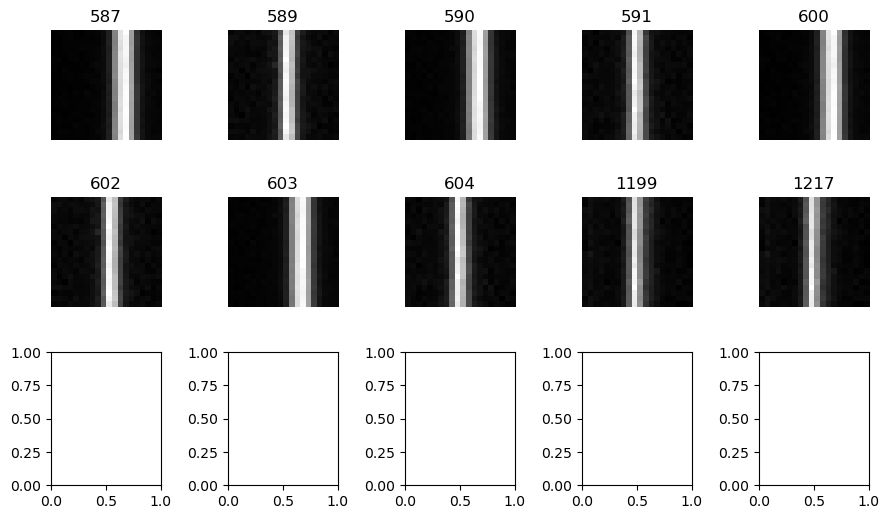

In [21]:
rff.inspect_df(dfs_neg['df_onestreak_neg'][:10], "direcname", fpath=fpath, extension="_1_implanted.npy")

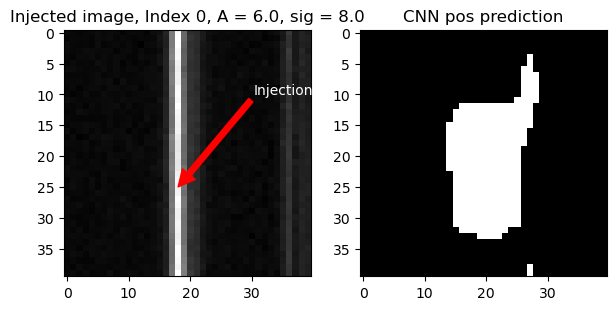

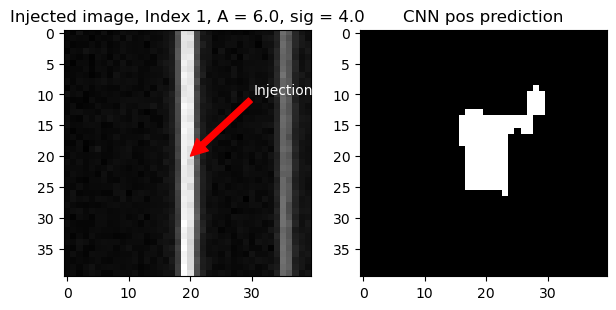

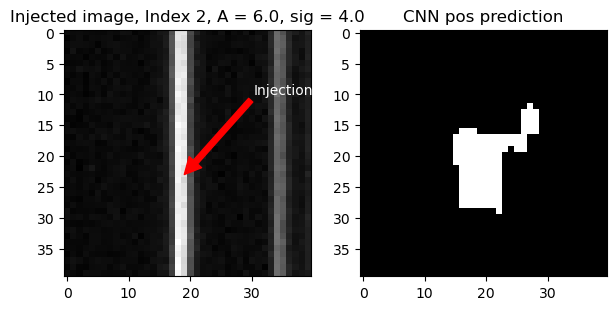

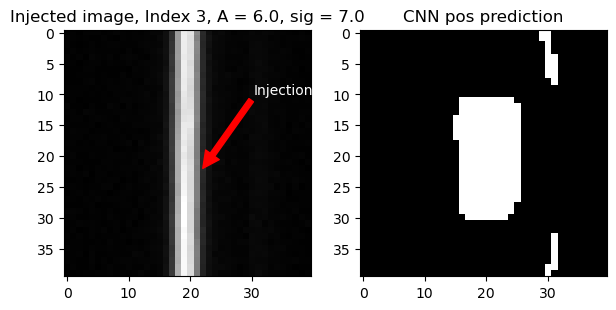

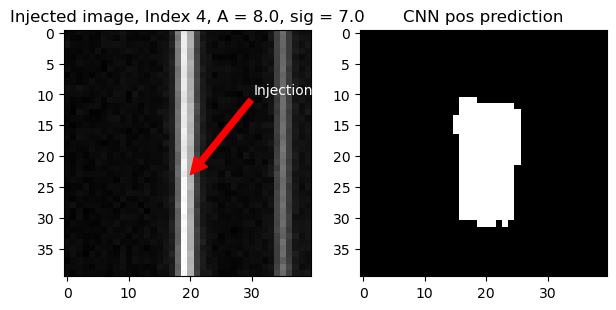

In [186]:
for index in dfs_pos['df_onestreak_pos'].index[:5]:
    inspect_stamp_and_map(dfs_pos['df_onestreak_pos'], index, "pos", size=20)

In [191]:
dfs_pos.keys()

dict_keys(['df_detections_pos_big', 'df_implants_pos_big', 'df_nocr_pos', 'df_reduced_edges_pos', 'df_reduced_edges_size4_pos', 'df_reducemax_pos', 'df_sobel_pos', 'df_snr_pos', 'df_snrall_pos', 'df_wstreaks_pos', 'df_onestreak_pos'])

In [196]:
dfs_pos['df_snr_pos']

,Unnamed: 0.3,Unnamed: 0.2,Unnamed: 0.1,Unnamed: 0,filename,detection_size,type,row_from_nn,col_from_nn,row_from_implant,col_from_implant,A_from_implant,sig_from_implant,quadrant,sobel_ratio,snr_center,snr_max,snr_min
0,0,286,288,288,ztf_20220820237546_000798_zr_c01_x_0003.,196,pos,2575.357143,143.117347,151.0,2588.0,8.0,5.0,1,20.633396,-0.341548,-0.043784,-3.880169
1,1,288,290,290,ztf_20220820237546_000798_zr_c01_x_0003.,161,pos,1561.732919,1031.652174,1045.0,1573.0,2.0,6.0,1,19.478168,0.145391,1.289850,-1.561340
2,2,289,291,291,ztf_20220820237546_000798_zr_c01_x_0003.,130,pos,946.723077,1872.200000,1880.0,959.0,4.0,4.0,1,14.145350,0.358458,2.631064,-1.519462
3,3,290,292,292,ztf_20220820237546_000798_zr_c01_x_0003.,270,pos,857.666667,2954.600000,2962.0,872.0,6.0,8.0,1,23.708256,-2.149451,0.586912,-2.368055
4,4,177,178,178,ztf_20220820237546_000798_zr_c02_x_0000.,91,pos,1685.593407,361.934066,371.0,1696.0,4.0,3.0,1,20.283700,-2.359664,-1.004060,-4.871979
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
894,897,935,938,938,ztf_20221020138241_000686_zi_c08_x_0014.,267,pos,2486.520599,1051.393258,1062.0,2500.0,8.0,9.0,1,22.012535,-0.001651,0.014021,-0.038418
895,898,936,939,939,ztf_20221020138241_000686_zi_c08_x_0014.,68,pos,2025.705882,1935.411765,1946.0,2036.0,3.0,4.0,1,25.341366,-1.140397,0.085987,-2.531263
896,899,937,940,940,ztf_20221020138241_000686_zi_c08_x_0014.,171,pos,1771.192982,2975.520468,2985.0,1784.0,8.0,9.0,1,30.613306,0.020615,1.629833,-0.029937
897,900,938,941,941,ztf_20221020138241_000686_zi_c08_x_0014.,242,pos,1570.483471,2377.041322,2388.0,1584.0,6.0,9.0,1,34.494305,-0.903966,-0.147733,-2.450859


In [205]:
len(np.unique(dfs_pos['df_snr_pos']['Unnamed: 0'])), len(dfs_pos['df_snr_pos']['Unnamed: 0'])

(899, 899)

In [208]:
snr_pos_not_onestreak_pos = []
for el in dfs_pos['df_snr_pos']['Unnamed: 0']:
    if el not in dfs_pos['df_onestreak_pos']['Unnamed: 0']:
        snr_pos_not_onestreak_pos.append(el)


In [209]:
snr_pos_not_onestreak_pos

[531,
 656,
 658,
 613,
 616,
 854,
 855,
 857,
 858,
 859,
 799,
 800,
 801,
 772,
 773,
 778,
 779,
 706,
 475,
 481,
 1091,
 1092,
 1095,
 1097,
 1098,
 1099,
 1106,
 1107,
 1108,
 1110,
 1111,
 1112,
 1074,
 1123,
 1124,
 1127,
 1128,
 1165,
 1168,
 1171,
 1331,
 1334,
 1336,
 1337,
 520,
 521,
 522,
 523,
 524,
 525,
 526,
 850,
 787,
 788,
 789,
 804,
 805,
 609,
 611,
 612,
 587,
 588,
 589,
 590,
 666,
 667,
 670,
 671,
 672,
 673,
 674,
 675,
 637,
 638,
 640,
 1222,
 1224,
 1189,
 1190,
 1193,
 1142,
 1143,
 1146,
 1296,
 1299,
 1300,
 1302,
 1268,
 1269,
 1270,
 1399,
 1400,
 1401,
 1404,
 1035,
 1036,
 1040,
 1041,
 1042,
 1043,
 1027,
 1029,
 1033,
 1086,
 1087,
 1089,
 1183,
 1186,
 1206,
 1209,
 1211,
 1213,
 1340,
 1343,
 1346,
 1306,
 1307,
 1312,
 1313,
 1314,
 973,
 977,
 780,
 782,
 783,
 784,
 785,
 622,
 624,
 625,
 696,
 697,
 698,
 699,
 700,
 701,
 538,
 539,
 540,
 541,
 543,
 544,
 606,
 608,
 1377,
 1378,
 1379,
 1243,
 1244,
 1246,
 1247,
 1249,
 1317,
 131

In [329]:
for name, df in dfs_neg.items():
    if name!= "df_implants_neg_big":
        newdf = df[df["type"]=="neg"]
        print(name, len(newdf))

df_detections_neg_big 622
df_nocr_neg 622
df_reduced_edges_neg 622
df_reduced_edges_size4_neg 478
df_reducemax_neg 370
df_sobel_neg 370
df_snr_neg 370
df_snrall_neg 370
df_wstreaks_neg 370
df_onestreak_neg 208


In [330]:
edges_neg_not_size4_neg = []

bigger = dfs_neg['df_reduced_edges_neg']
smaller = dfs_neg['df_reduced_edges_size4_neg']

intlist_row = [ int(x) for x in smaller["row_from_nn"]]
intlist_col = [ int(x) for x in smaller["col_from_nn"]]

for index in bigger.index:
    # print(index)
    # print(bigger["row_from_nn"].iloc[index])
    # break
    if int(bigger["row_from_nn"].iloc[index]) not in intlist_row:
        print("true row")
        edges_neg_not_size4_neg.append(index)
    elif int(bigger["col_from_nn"].iloc[index]) not in intlist_col:
        print("true col")
        edges_neg_not_size4_neg.append(index)
        


true row
true row
true row
true row
true row
true row
true row
true row
true row
true row
true col
true row
true row
true row
true col
true row
true row
true row
true col
true row
true row
true col
true row
true row
true row
true col
true row
true row
true row
true row
true row
true row
true row
true row
true row
true row
true col
true row
true row
true row
true col
true row
true row
true row
true col
true row
true row
true row
true row
true row
true row
true row
true col
true row
true row
true row
true row
true row
true col
true row
true row
true row
true row
true row
true row
true row
true row
true row
true row
true row
true col
true row
true row
true row
true row
true row
true row
true row
true row
true col
true row
true row
true row
true row
true row
true row
true row
true row
true row
true row
true row
true col
true row
true row
true row
true row
true col
true col
true row
true row
true row
true row
true row
true row
true row
true col
true row
true row
true row
true col
true row
t

In [331]:
len(edges_neg_not_size4_neg)

290

In [296]:
reduced_edges_size4_pos_not_reducemax_pos = []

bigger = dfs_pos['df_reduced_edges_size4_pos']
smaller = dfs_pos['df_reducemax_pos']

intlist_row = [ int(x) for x in smaller["row_from_nn"]]
intlist_col = [ int(x) for x in smaller["col_from_nn"]]

for index in bigger.index:
    # print(index)
    # print(bigger["row_from_nn"].iloc[index])
    # break
    if int(bigger["row_from_nn"].iloc[index]) not in intlist_row:
        print("true row")
        reduced_edges_size4_pos_not_reducemax_pos.append(index)
    elif int(bigger["col_from_nn"].iloc[index]) not in intlist_col:
        print("true col")
        reduced_edges_size4_pos_not_reducemax_pos.append(index)
        


true col
true row
true row
true col
true row
true col
true row
true row
true col
true row
true col
true row
true row
true row
true row
true row
true row
true col
true row
true row
true row
true row
true row
true row
true row
true row
true row
true row
true row
true row
true col
true row
true col
true row
true row
true row
true col
true row
true row
true col
true row
true col
true row
true row
true row
true row
true row
true row
true row
true col
true row
true row
true col
true col
true col
true row
true col
true row
true row
true row
true row
true row
true row
true row
true row
true row
true row
true row
true col
true row
true row
true col
true row
true row
true col
true row
true row
true row
true col
true row
true row
true row
true row
true col
true col
true row
true row
true row
true row
true row
true row
true col
true col
true row
true row
true row
true col
true row
true row
true row
true row
true row
true row
true row
true row
true row
true row
true col
true row
true col
true col
t

In [297]:
len(reduced_edges_size4_pos_not_reducemax_pos)

451

In [302]:
reduced_edges_size4_neg_not_reducemax_neg = []

bigger = dfs_neg['df_reduced_edges_size4_neg']
smaller = dfs_neg['df_reducemax_neg']

intlist_row = [ int(x) for x in smaller["row_from_nn"]]
intlist_col = [ int(x) for x in smaller["col_from_nn"]]

for index in bigger.index:
    # print(index)
    # print(bigger["row_from_nn"].iloc[index])
    # break
    if int(bigger["row_from_nn"].iloc[index]) not in intlist_row:
        print("true row")
        reduced_edges_size4_neg_not_reducemax_neg.append(index)
    elif int(bigger["col_from_nn"].iloc[index]) not in intlist_col:
        print("true col")
        reduced_edges_size4_neg_not_reducemax_neg.append(index)
        


true row
true row
true row
true row
true col
true row
true row
true row
true row
true row
true row
true row
true row
true row
true row
true row
true row
true row
true row
true row
true row
true row
true row
true row
true col
true row
true row
true col
true row
true row
true row
true col
true row
true row
true row
true row
true row
true row
true row
true row
true row
true row
true col
true row
true row
true row
true row
true row
true col
true col
true col
true row
true row
true row
true row
true row
true row
true row
true row
true row
true row
true row
true col
true row
true row
true row
true row
true row
true row
true row
true row
true row
true row
true col
true row
true row
true col
true row
true row
true row
true row
true row
true row
true row
true col
true row
true row
true row
true row
true row
true row
true row
true row
true row
true row
true row
true row
true col
true row
true row
true row
true row
true row
true row
true row
true row
true row
true row
true row
true col
true row
t

In [298]:
snr_pos_not_onestreak_pos = []

bigger = dfs_pos['df_snr_pos']
smaller = dfs_pos['df_onestreak_pos']

intlist_row = [ int(x) for x in smaller["row_from_nn"]]
intlist_col = [ int(x) for x in smaller["col_from_nn"]]

for index in bigger.index:
    # print(index)
    # print(bigger["row_from_nn"].iloc[index])
    # break
    if int(bigger["row_from_nn"].iloc[index]) not in intlist_row:
        print("true row")
        snr_pos_not_onestreak_pos.append(index)
    elif int(bigger["col_from_nn"].iloc[index]) not in intlist_col:
        print("true col")
        snr_pos_not_onestreak_pos.append(index)
        


true col
true row
true row
true row
true row
true row
true row
true row
true col
true row
true row
true row
true row
true row
true row
true row
true row
true row
true row
true row
true row
true row
true row
true row
true row
true row
true row
true col
true row
true col
true row
true row
true col
true row
true row
true col
true row
true row
true row
true row
true row
true col
true col
true row
true row
true row
true row
true col
true row
true row
true row
true row
true col
true col
true row
true row
true row
true row
true col
true row
true row
true row
true row
true row
true row
true row
true row
true row
true row
true row
true col
true row
true row
true row
true row
true row
true row
true row
true row
true row
true row
true row
true row
true row
true col
true row
true row
true row
true row
true row
true row
true row
true row
true row
true row
true row
true row
true col
true row
true col
true row
true row
true row
true row
true row
true row
true row
true row
true row
true row
true row
t

In [291]:
len(intlist_col)

471

In [ ]:
sobel_pos_not_snr_pos = []

bigger = dfs_pos['df_sobel_pos']
smaller = dfs_pos['df_snr_pos']

intlist_row = [ int(x) for x in smaller["row_from_nn"]]
intlist_col = [ int(x) for x in smaller["col_from_nn"]]

for index in bigger.index:
    # print(index)
    # print(bigger["row_from_nn"].iloc[index])
    # break
    if int(bigger["row_from_nn"].iloc[index]) not in intlist_row:
        print("true row")
        sobel_pos_not_snr_pos.append(index)
    elif int(bigger["col_from_nn"].iloc[index]) not in intlist_col:
        print("true col")
        sobel_pos_not_snr_pos.append(index)
        


In [299]:
sobel_pos_not_snr_pos = []

bigger = dfs_pos['df_sobel_pos']
smaller = dfs_pos['df_snr_pos']

intlist_row = [ int(x) for x in smaller["row_from_nn"]]
intlist_col = [ int(x) for x in smaller["col_from_nn"]]

for index in bigger.index:
    # print(index)
    # print(bigger["row_from_nn"].iloc[index])
    # break
    if int(bigger["row_from_nn"].iloc[index]) not in intlist_row:
        print("true row")
        sobel_pos_not_snr_pos.append(index)
    elif int(bigger["col_from_nn"].iloc[index]) not in intlist_col:
        print("true col")
        sobel_pos_not_snr_pos.append(index)
        


true row
true row
true row


In [285]:
sobel_pos_not_snr_pos

[412, 753, 890]

In [237]:
dfs_pos['df_sobel_pos']

,Unnamed: 0.3,Unnamed: 0.2,Unnamed: 0.1,Unnamed: 0,filename,detection_size,type,row_from_nn,col_from_nn,row_from_implant,col_from_implant,A_from_implant,sig_from_implant,quadrant,sobel_ratio
0,0,286,288,288,ztf_20220820237546_000798_zr_c01_x_0003.,196,pos,2575.357143,143.117347,151.0,2588.0,8.0,5.0,1,20.633396
1,1,288,290,290,ztf_20220820237546_000798_zr_c01_x_0003.,161,pos,1561.732919,1031.652174,1045.0,1573.0,2.0,6.0,1,19.478168
2,2,289,291,291,ztf_20220820237546_000798_zr_c01_x_0003.,130,pos,946.723077,1872.200000,1880.0,959.0,4.0,4.0,1,14.145350
3,3,290,292,292,ztf_20220820237546_000798_zr_c01_x_0003.,270,pos,857.666667,2954.600000,2962.0,872.0,6.0,8.0,1,23.708256
4,4,177,178,178,ztf_20220820237546_000798_zr_c02_x_0000.,91,pos,1685.593407,361.934066,371.0,1696.0,4.0,3.0,1,20.283700
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
897,897,935,938,938,ztf_20221020138241_000686_zi_c08_x_0014.,267,pos,2486.520599,1051.393258,1062.0,2500.0,8.0,9.0,1,22.012535
898,898,936,939,939,ztf_20221020138241_000686_zi_c08_x_0014.,68,pos,2025.705882,1935.411765,1946.0,2036.0,3.0,4.0,1,25.341366
899,899,937,940,940,ztf_20221020138241_000686_zi_c08_x_0014.,171,pos,1771.192982,2975.520468,2985.0,1784.0,8.0,9.0,1,30.613306
900,900,938,941,941,ztf_20221020138241_000686_zi_c08_x_0014.,242,pos,1570.483471,2377.041322,2388.0,1584.0,6.0,9.0,1,34.494305


In [244]:
dfs_pos['df_snr_pos']

,Unnamed: 0.3,Unnamed: 0.2,Unnamed: 0.1,Unnamed: 0,filename,detection_size,type,row_from_nn,col_from_nn,row_from_implant,col_from_implant,A_from_implant,sig_from_implant,quadrant,sobel_ratio,snr_center,snr_max,snr_min
0,0,286,288,288,ztf_20220820237546_000798_zr_c01_x_0003.,196,pos,2575.357143,143.117347,151.0,2588.0,8.0,5.0,1,20.633396,-0.341548,-0.043784,-3.880169
1,1,288,290,290,ztf_20220820237546_000798_zr_c01_x_0003.,161,pos,1561.732919,1031.652174,1045.0,1573.0,2.0,6.0,1,19.478168,0.145391,1.289850,-1.561340
2,2,289,291,291,ztf_20220820237546_000798_zr_c01_x_0003.,130,pos,946.723077,1872.200000,1880.0,959.0,4.0,4.0,1,14.145350,0.358458,2.631064,-1.519462
3,3,290,292,292,ztf_20220820237546_000798_zr_c01_x_0003.,270,pos,857.666667,2954.600000,2962.0,872.0,6.0,8.0,1,23.708256,-2.149451,0.586912,-2.368055
4,4,177,178,178,ztf_20220820237546_000798_zr_c02_x_0000.,91,pos,1685.593407,361.934066,371.0,1696.0,4.0,3.0,1,20.283700,-2.359664,-1.004060,-4.871979
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
894,897,935,938,938,ztf_20221020138241_000686_zi_c08_x_0014.,267,pos,2486.520599,1051.393258,1062.0,2500.0,8.0,9.0,1,22.012535,-0.001651,0.014021,-0.038418
895,898,936,939,939,ztf_20221020138241_000686_zi_c08_x_0014.,68,pos,2025.705882,1935.411765,1946.0,2036.0,3.0,4.0,1,25.341366,-1.140397,0.085987,-2.531263
896,899,937,940,940,ztf_20221020138241_000686_zi_c08_x_0014.,171,pos,1771.192982,2975.520468,2985.0,1784.0,8.0,9.0,1,30.613306,0.020615,1.629833,-0.029937
897,900,938,941,941,ztf_20221020138241_000686_zi_c08_x_0014.,242,pos,1570.483471,2377.041322,2388.0,1584.0,6.0,9.0,1,34.494305,-0.903966,-0.147733,-2.450859


ztf_20220820237546_000798_zr_c04_x_0003.


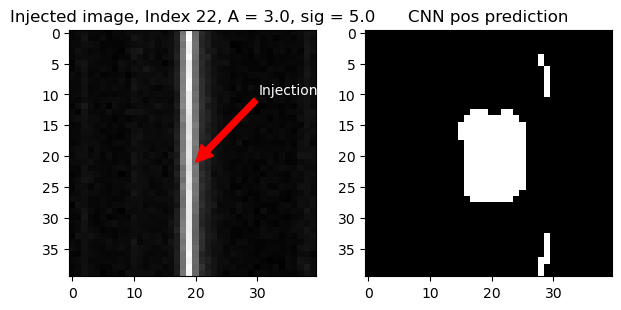

ztf_20220820237546_000798_zr_c04_x_0004.


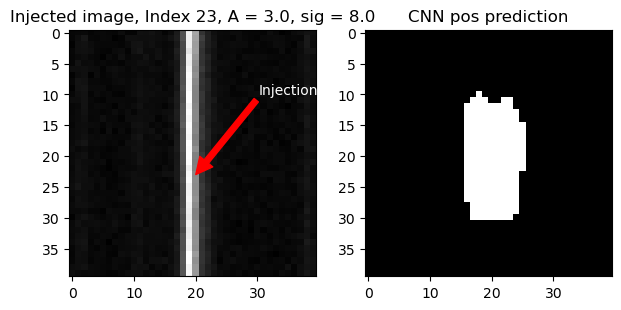

ztf_20220820237546_000798_zr_c04_x_0004.


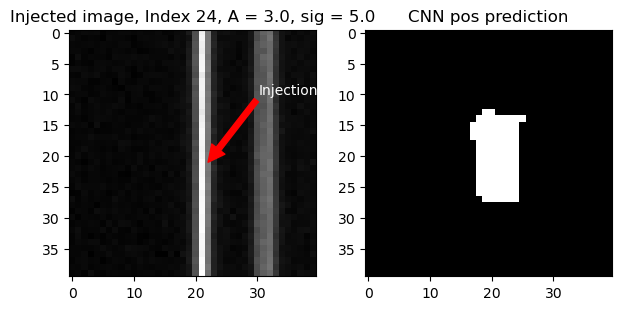

ztf_20220820237546_000798_zr_c05_x_0002.


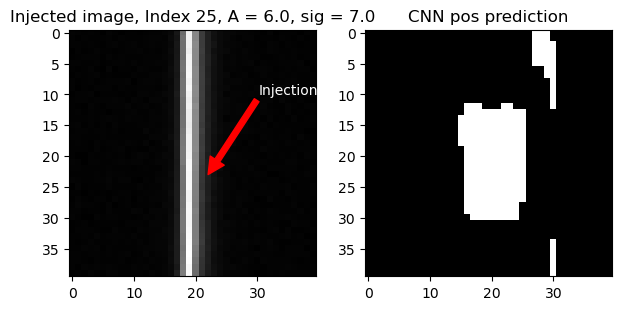

ztf_20220820237546_000798_zr_c05_x_0002.


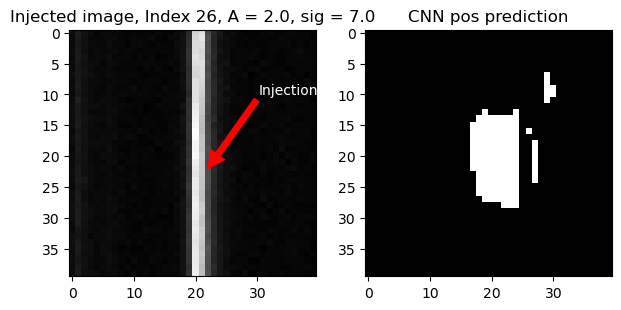

In [231]:
for index in snr_pos_not_onestreak_pos[:5]:
    inspect_stamp_and_map(dfs_pos['df_snr_pos'], index, "pos", size=20, column="Unnamed: 0")

In [287]:
len(snr_pos_not_onestreak_pos)

68

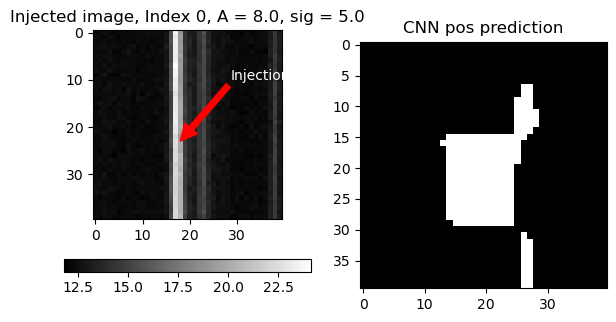

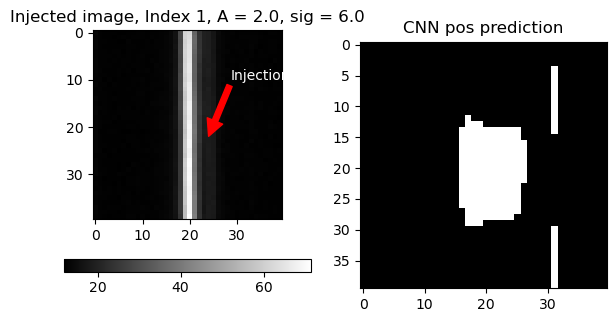

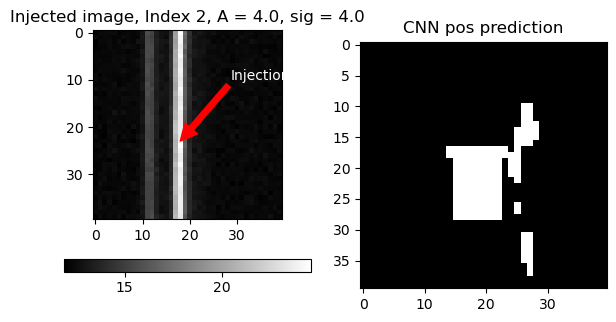

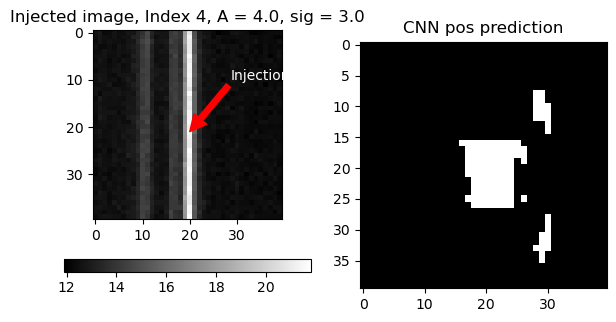

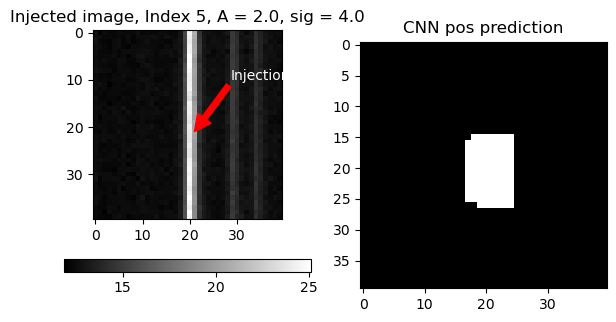

In [316]:

for index in snr_pos_not_onestreak_pos[:5]:
    inspect_stamp_and_map(dfs_pos['df_snr_pos'], index, "pos", size=20, column=None)

In [282]:
sobel_pos_not_snr_pos

[412,
 753,
 890,
 1,
 2,
 4,
 5,
 6,
 7,
 8,
 10,
 11,
 12,
 13,
 20,
 24,
 28,
 31,
 42,
 44,
 50,
 54,
 56,
 58,
 60,
 63,
 66,
 68,
 71,
 73,
 77,
 79,
 80,
 89,
 92,
 95,
 97,
 98,
 104,
 106,
 108,
 112,
 131,
 132,
 145,
 146,
 155,
 158,
 159,
 162,
 172,
 180,
 181,
 186,
 188,
 190,
 244,
 269,
 273,
 275,
 279,
 291,
 294,
 296,
 300,
 301,
 303,
 306,
 308,
 310,
 311,
 316,
 317,
 323,
 332,
 338,
 345,
 350,
 355,
 357,
 358,
 359,
 360,
 361,
 364,
 365,
 368,
 372,
 373,
 374,
 375,
 376,
 377,
 379,
 380,
 382,
 383,
 384,
 385,
 393,
 397,
 398,
 401,
 404,
 407,
 409,
 411,
 412,
 413,
 414,
 415,
 417,
 418,
 420,
 421,
 425,
 427,
 428,
 430,
 431,
 437,
 438,
 440,
 442,
 444,
 445,
 448,
 449,
 451,
 454,
 455,
 456,
 458,
 459,
 460,
 462,
 464,
 466,
 467,
 468,
 470,
 473,
 476,
 478,
 482,
 483,
 484,
 489,
 491,
 494,
 496,
 502,
 506,
 516,
 517,
 520,
 522,
 524,
 528,
 530,
 531,
 532,
 536,
 539,
 540,
 541,
 545,
 546,
 548,
 550,
 552,
 554,
 555,
 556

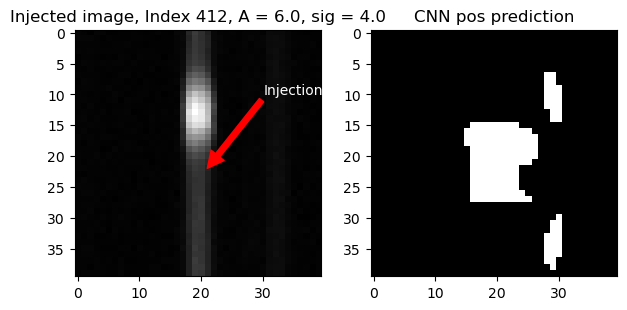

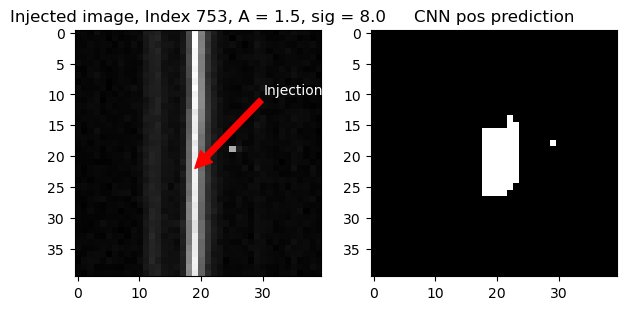

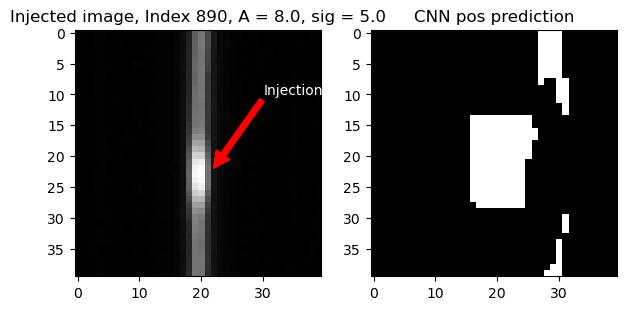

In [286]:
for index in sobel_pos_not_snr_pos[:5]:
    inspect_stamp_and_map(dfs_pos['df_sobel_pos'], index, "pos", size=20, column=None)

In [322]:
dfs_pos['df_reduced_edges_size4_pos'].iloc[8]

Unnamed: 0.2                                               8
Unnamed: 0.1                                               8
Unnamed: 0                                                 8
filename            ztf_20220820237546_000798_zr_c14_x_0004.
detection_size                                           107
type                                                     pos
row_from_nn                                       147.906542
col_from_nn                                      1700.336449
row_from_implant                                      1710.0
col_from_implant                                       160.0
A_from_implant                                           2.0
sig_from_implant                                         8.0
Name: 8, dtype: object

In [323]:
image = np.load(fpath+"ztf_20220820237546_000798_zr_c14_x_0004."+"_1_implanted.npy")

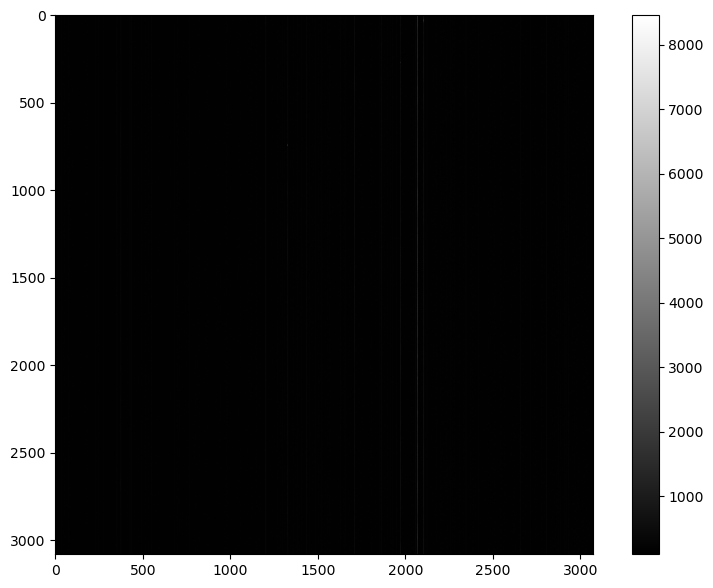

In [326]:
plt.imshow(image)
plt.colorbar()

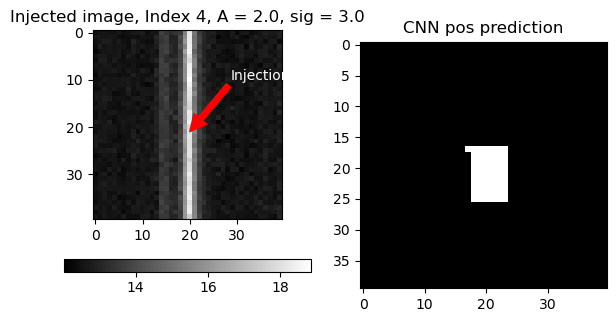

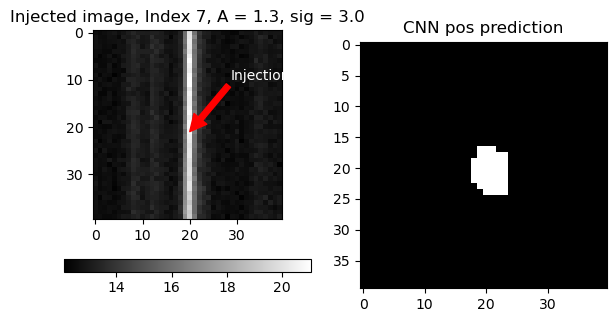

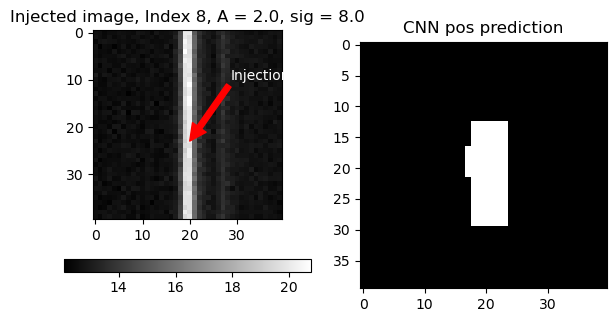

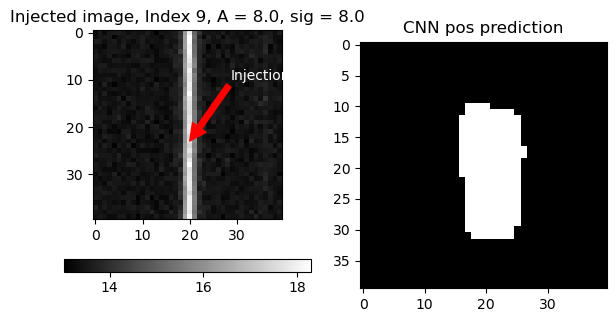

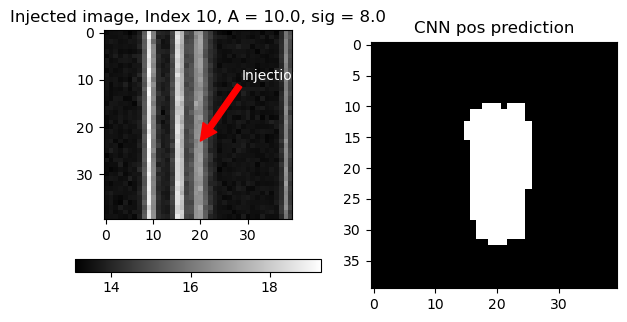

In [321]:

for index in reduced_edges_size4_pos_not_reducemax_pos[:5]:
    inspect_stamp_and_map(dfs_pos['df_reduced_edges_size4_pos'], index, "pos", size=20, column=None)

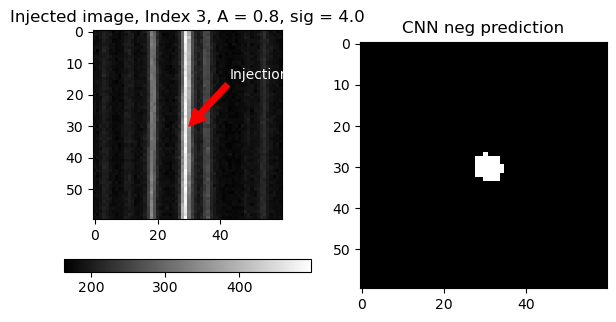

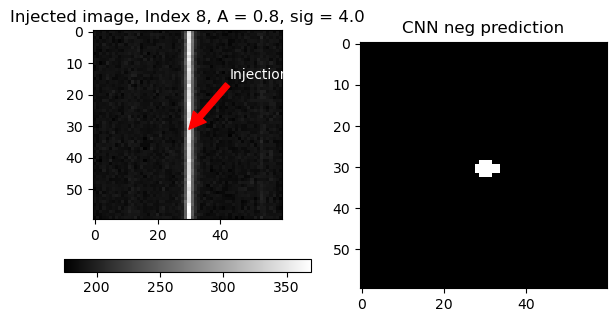

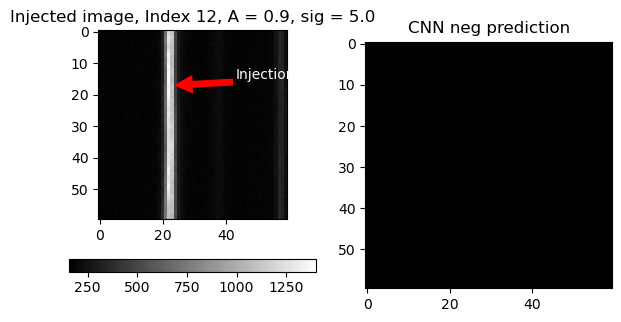

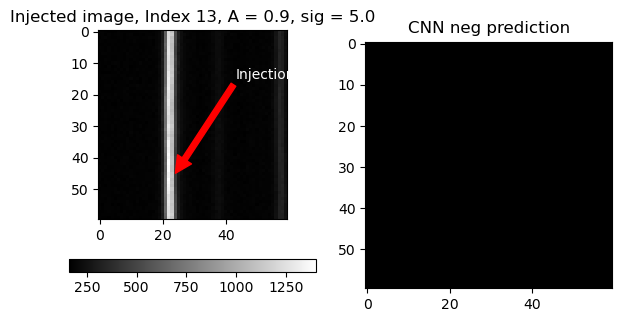

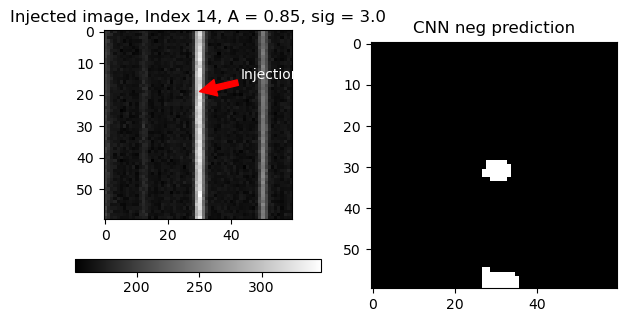

In [328]:

for index in reduced_edges_size4_neg_not_reducemax_neg[:5]:
    inspect_stamp_and_map(dfs_neg['df_reduced_edges_size4_neg'], index, "neg", size=30, column=None)

In [332]:
dfs_neg.keys()

dict_keys(['df_detections_neg_big', 'df_implants_neg_big', 'df_nocr_neg', 'df_reduced_edges_neg', 'df_reduced_edges_size4_neg', 'df_reducemax_neg', 'df_sobel_neg', 'df_snr_neg', 'df_snrall_neg', 'df_wstreaks_neg', 'df_onestreak_neg'])

In [338]:
fpath

'/lustre/lrspec/ZTF_data/training_aug24/full_image_implantations/fullrange/images/'

In [342]:
np.min(dfs_neg['df_reduced_edges_neg']["detection_size"])

1

In [402]:
dfs_neg['df_reduced_edges_neg'].iloc[6]

Unnamed: 0.2                                               6
Unnamed: 0.1                                               6
Unnamed: 0                                                 6
filename            ztf_20221014162894_000802_zg_c01_x_0029.
detection_size                                             3
type                                                     pos
row_from_nn                                           1207.0
col_from_nn                                            543.0
row_from_implant                                       556.0
col_from_implant                                      1208.0
A_from_implant                                          0.85
sig_from_implant                                         3.0
Name: 6, dtype: object

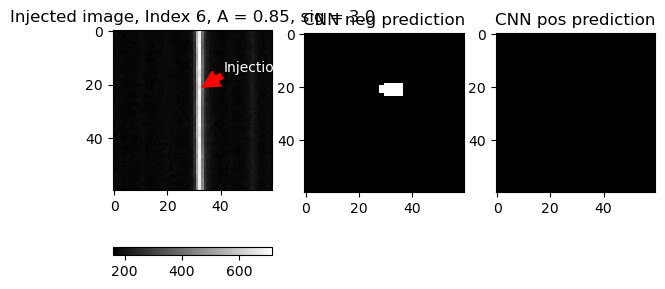

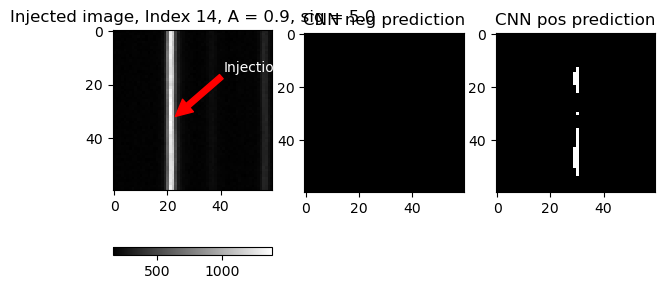

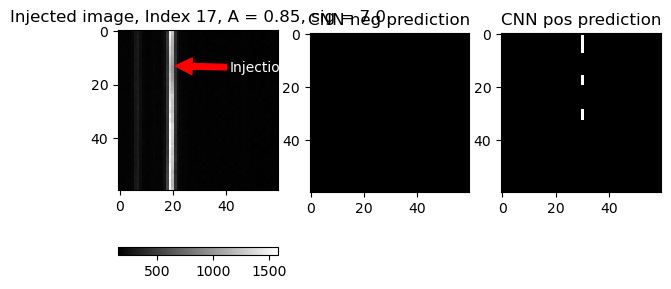

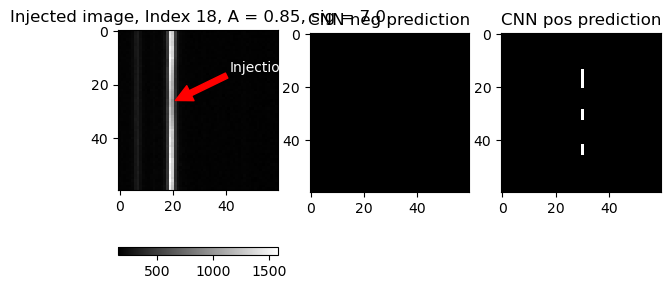

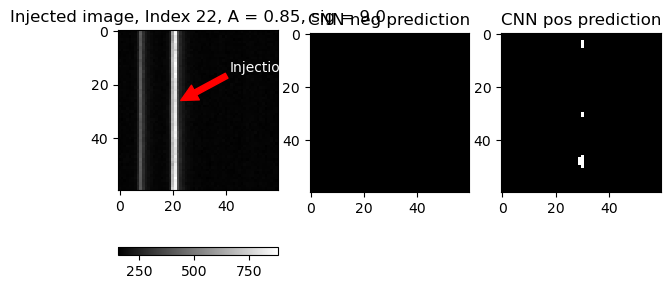

In [400]:
for index in edges_neg_not_size4_neg[:5]:
    inspect_stamp_and_map(dfs_neg['df_reduced_edges_neg'], index, "neg", size=30, column=None)

In [344]:
edges_neg_not_size4_neg[1]

14

In [346]:
dfs_neg['df_reduced_edges_neg'].iloc[14]

Unnamed: 0.2                                              14
Unnamed: 0.1                                              16
Unnamed: 0                                                16
filename            ztf_20221014162894_000802_zg_c02_x_0022.
detection_size                                             1
type                                                     pos
row_from_nn                                            494.0
col_from_nn                                           1555.0
row_from_implant                                      1558.0
col_from_implant                                       506.0
A_from_implant                                           0.9
sig_from_implant                                         5.0
Name: 14, dtype: object

In [350]:
    ppath = "/lustre/lrspec/ZTF_data/training_aug24/full_image_implantations/predsarrays/"


In [352]:
nrow, ncol = image.shape

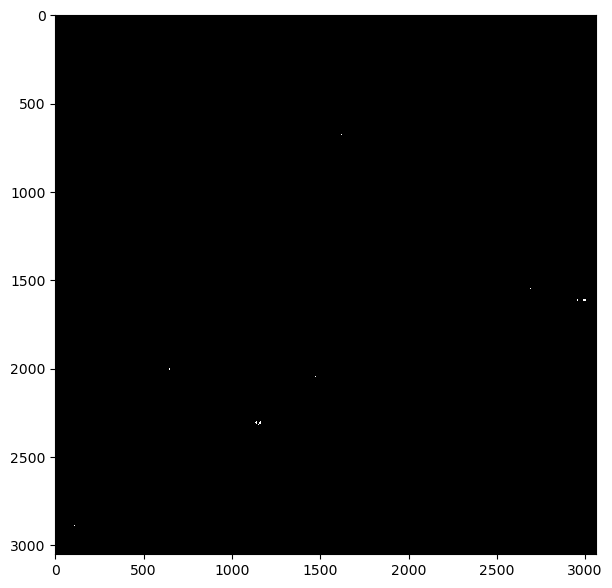

In [395]:
index=14
df = dfs_neg['df_reduced_edges_neg']
pfile = df.iloc[index]["filename"]+"_extraction_predsarray_predsarray.npy"
predsarray = np.load(ppath+pfile)
pimg = predsarray[:, 2].reshape(ncol - 2 * wid, nrow - 2 * wid)
plt.imshow(
    pimg>.9999)

In [406]:
index=14

def compare_preds(index):
    df = dfs_neg['df_reduced_edges_neg']
    pfile = df.iloc[index]["filename"]+"_extraction_predsarray_neg_predsarray.npy"
    predsarray = np.load(ppath+pfile)
    pimg = predsarray[:, 2].reshape(ncol - 2 * wid, nrow - 2 * wid)

    fig, ax = plt.subplots(1,2)
    ax[0].imshow(
        pimg>.9999)
    pfile2 = df.iloc[index]["filename"]+"_extraction_predsarray_predsarray.npy"
    predsarray2 = np.load(ppath+pfile2)
    pimg2 = predsarray2[:, 2].reshape(ncol - 2 * wid, nrow - 2 * wid)
    ax[1].imshow(
        pimg2>.9999)        

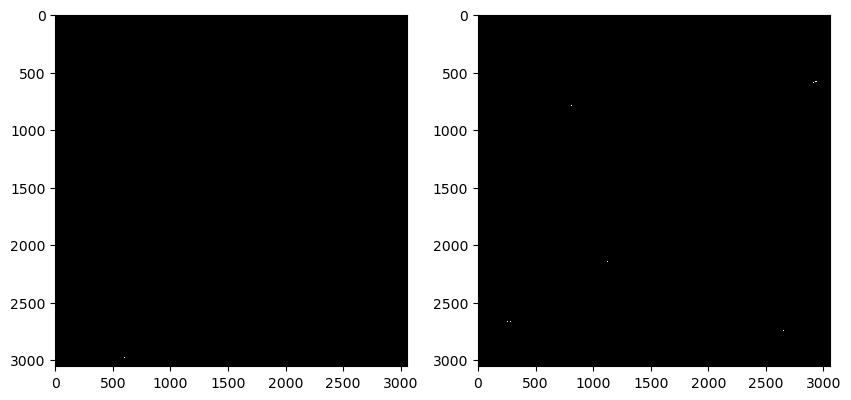

In [410]:
compare_preds(11)

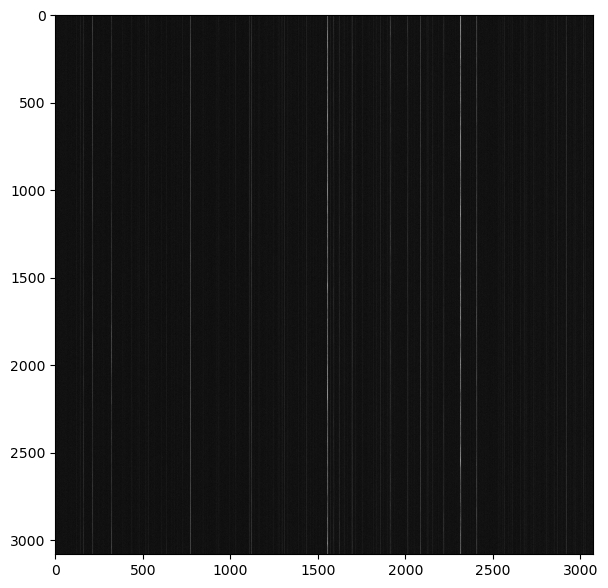

In [364]:
index=14
df = dfs_neg['df_reduced_edges_neg']
file = df.iloc[index]["filename"]+"_1_implanted.npy"
array = np.load(fpath+file)
plt.imshow(np.sqrt(array))

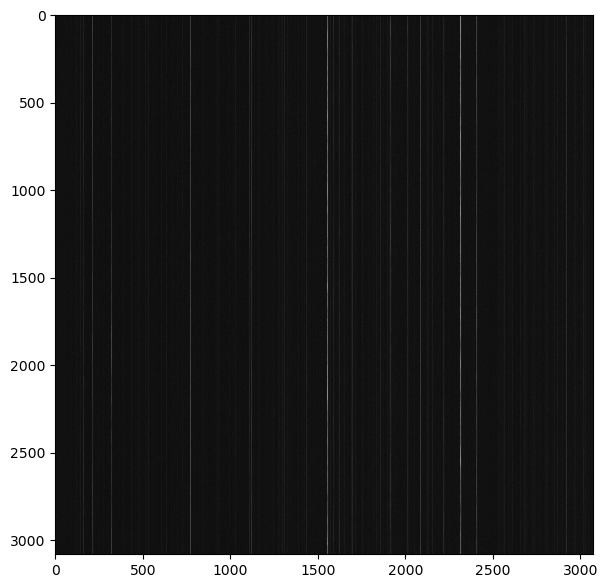

In [365]:
index=14
df = dfs_neg['df_reduced_edges_neg']
file = df.iloc[index]["filename"]+"_1_implanted_neg.npy"
array = np.load(fpath+file)
plt.imshow(np.sqrt(array))

In [378]:
infpath = "/lustre/lrspec/ZTF_data/training_aug24/full_image_implantations/fullrange/info/"

'ztf_20221014162894_000802_zg_c02_x_0022.'

In [381]:
index=14
df = dfs_neg['df_reduced_edges_neg']
file = df.iloc[index]["filename"]+"_1_implanted_info_neg.npy"
array = np.load(infpath+file)
print(array)

[[3.210e+02 1.070e+03 9.900e-01 5.000e+00]
 [1.558e+03 5.060e+02 9.900e-01 5.000e+00]
 [1.622e+03 1.553e+03 9.900e-01 4.000e+00]
 [1.918e+03 8.190e+02 8.500e-01 5.000e+00]
 [2.015e+03 2.729e+03 8.000e-01 5.000e+00]
 [2.216e+03 1.436e+03 9.500e-01 5.000e+00]
 [2.319e+03 2.249e+03 9.000e-01 4.000e+00]
 [2.407e+03 1.489e+03 8.500e-01 4.000e+00]]


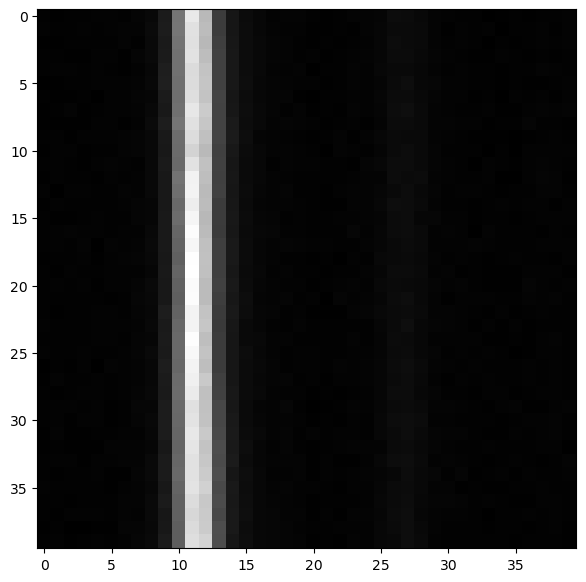

In [386]:
row = int(df.iloc[index]["row_from_nn"])
col = int(df.iloc[index]["col_from_nn"])
fpath = '/lustre/lrspec/ZTF_data/training_aug24/full_image_implantations/fullrange/images/'
fname = df.iloc[index]["filename"]+"_1_implanted.npy"
path = fpath + fname
array = np.load(path)
imj = plt.imshow(
            
                array[
                    row - size + wid : row + size + wid,
                    col + wid - size : col + wid + size,
                ]
            
            )

In [391]:
dfs_neg['df_reduced_edges_neg'].iloc[index]

Unnamed: 0.2                                              14
Unnamed: 0.1                                              16
Unnamed: 0                                                16
filename            ztf_20221014162894_000802_zg_c02_x_0022.
detection_size                                             1
type                                                     pos
row_from_nn                                            494.0
col_from_nn                                           1555.0
row_from_implant                                      1558.0
col_from_implant                                       506.0
A_from_implant                                           0.9
sig_from_implant                                         5.0
Name: 14, dtype: object

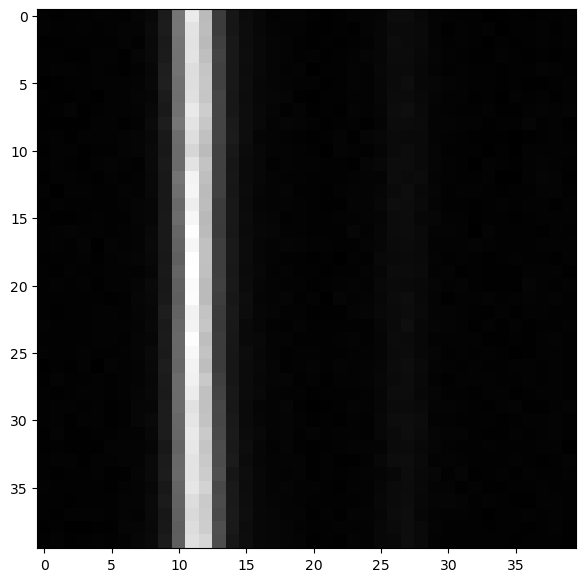

In [390]:
row = int(df.iloc[index]["row_from_nn"])
col = int(df.iloc[index]["col_from_nn"])
fpath = '/lustre/lrspec/ZTF_data/training_aug24/full_image_implantations/fullrange/images/'
fname = df.iloc[index]["filename"]+"_1_implanted_neg.npy"
path = fpath + fname
array2 = np.load(path)
plt.imshow(
            
                array2[
                    row - size + wid : row + size + wid,
                    col + wid - size : col + wid + size,
                ]
            
            )

In [403]:
direcs = ["/lustre/lrspec/ZTF_data/training_aug24/full_image_implantations/images/"]



for j in range(len(direcs)):
    direc = direcs[j]
    # model = model_best
    wid = 10
    abst_thr = .9999
    fpath_extractions = "/lustre/lrspec/ZTF_data/training_aug24/full_image_implantations/predsarrays/"


    for i, file in enumerate(os.listdir(direc)):
        image_filename = os.fsdecode(file)
        filename_start = image_filename[:40]
        image_filename_full = direc+image_filename
        if os.path.isfile(fpath_extractions+str(filename_start)+"_extraction_predsarray_predsarray_neg.npy"):
            print("skipping ",filename_start)
            continue

        print(image_filename_full)
        file1_array = np.load(image_filename_full)
        norm = (file1_array-np.min(file1_array))/(np.max(file1_array)-np.min(file1_array))
        image = norm
        nrow, ncol = image.shape
        path = fpath_extractions+str(filename_start)+"_extraction_predsarray_neg"


/lustre/lrspec/ZTF_data/training_aug24/full_image_implantations/images/ztf_20221020138241_000686_zi_c06_x_0025._1_implanted.npy
/lustre/lrspec/ZTF_data/training_aug24/full_image_implantations/images/ztf_20221014162894_000802_zg_c02_x_0013._1_implanted.npy
/lustre/lrspec/ZTF_data/training_aug24/full_image_implantations/images/ztf_20221014162894_000802_zg_c02_x_0016._1_implanted_neg.npy
/lustre/lrspec/ZTF_data/training_aug24/full_image_implantations/images/ztf_20221020138241_000686_zi_c07_x_0013._1_implanted.npy
/lustre/lrspec/ZTF_data/training_aug24/full_image_implantations/images/ztf_20220820237546_000798_zr_c15_x_0002._1_implanted_neg.npy
/lustre/lrspec/ZTF_data/training_aug24/full_image_implantations/images/ztf_20221017148750_000831_zi_c01_x_0009._1_implanted_neg.npy
/lustre/lrspec/ZTF_data/training_aug24/full_image_implantations/images/ztf_20220820237546_000798_zr_c14_x_0003._1_implanted.npy
/lustre/lrspec/ZTF_data/training_aug24/full_image_implantations/images/ztf_20221020138241_00

KeyboardInterrupt: 